# Fernando Cipriani
# Curso de Machine Learning 2026
# Parte 2B — Los modelos y la comparación final


**Este cuaderno está armado para que sea muy fácil modificarlo o extenderlo.** Evalúa doce
modelos de clasificación (la lista completa está en el índice), uno por celda, pero las doce
celdas son prácticamente idénticas: cada una declara solo lo que le es propio a ese modelo —tres
líneas de pipeline y una grilla de hiperparámetros— y llama a una misma función,
`evaluar_modelo()`, que hace todo el resto. Agregar un modelo trece es, literalmente, copiar una
de esas celdas y cambiar esas pocas líneas (el punto 9.9 explica exactamente cuáles).

Eso es posible porque todo lo que **no** cambia de un modelo a otro está resuelto una sola vez,
antes de llegar al primero (puntos 8 y 9):

*  **Los criterios de evaluación son parámetros**, no están repetidos en cada celda: la métrica
   que decide cuál es la mejor combinación de hiperparámetros (y una segunda, solo informativa), y
   los umbrales que definen cuándo hay sobreajuste, subajuste o inestabilidad, se declaran una sola
   vez y se aplican igual a los doce modelos.
*  **Las piezas que se repiten están escritas una sola vez**: armar y correr la búsqueda de
   hiperparámetros, escalar los datos, reducir dimensiones con PCA, calcular las métricas,
   diagnosticar el ajuste y dibujar el panel de gráficos de cada modelo.

Con esa base, el cuaderno recorre los doce modelos con la misma vara de medir. Al final (punto 22)
los compara a todos con esa misma métrica definida de entrada, muestra el mejor puntuado, y
exporta un archivo con el ranking completo y todos los parámetros elegidos —incluida la semilla y
la cantidad de pliegues— para poder reproducir exactamente esta comparación más adelante.

Acá no se define nada nuevo sobre cómo medir —eso ya quedó resuelto en la Parte 2A— sino que se
usa ese criterio una y otra vez. La numeración sigue la de la Parte 2A sin reiniciarse: este
cuaderno arranca en el punto 7 y llega hasta el 22.

**Qué necesita para arrancar**

El archivo que dejó la Parte 2A (o, en su defecto, el dataset original — el punto 7.2 explica las
dos alternativas). No hace falta tenerlo descargado: por defecto el cuaderno lo lee directamente
del repositorio de GitHub del proyecto, así que se abre y se ejecuta.

**Las librerías se importan por bloques**, justo antes de la sección que las usa, igual que en la
Parte 2A.

---
# Índice — Parte 2B

### 7. Continuidad desde la Parte 2A
- [7.1 Qué necesita este cuaderno](#sec-7-1)
- [7.2 Recuperar los datos](#sec-7-2)
- [7.3 Variables predictoras, objetivo y matrices X, y](#sec-7-3)

### 8. Métricas y diagnóstico de resultados
- [8.1 Qué métricas se calculan](#sec-8-1)
- [8.2 Diagnóstico automático de ajuste](#sec-8-2)
- [8.3 El panel de seis gráficos](#sec-8-3)

### 9. El motor de búsqueda de hiperparámetros
- [9.1 Las alternativas de PCA](#sec-9-1)
- [9.2 Las alternativas de escalado](#sec-9-2)
- [9.3 Etiquetas legibles y la búsqueda de grilla](#sec-9-3)
- [9.4 El criterio de decisión: la cota inferior](#sec-9-4)
- [9.5 Dónde se acumulan los resultados](#sec-9-5)
- [9.6 Reconstruir el pipeline elegido](#sec-9-6)
- [9.7 El texto de resultados](#sec-9-7)
- [9.8 El orquestador de todo el proceso](#sec-9-8)
- [9.9 La plantilla genérica de cada modelo](#sec-9-9)

### 10. Regresión Logística
- [La celda del modelo](#sec-10)

### 11. SVM (Máquinas de Vectores de Soporte)
- [La celda del modelo](#sec-11)

### 12. K-Vecinos (KNN)
- [La celda del modelo](#sec-12)

### 13. Árbol de Decisión
- [La celda del modelo](#sec-13)

### 14. Random Forest
- [La celda del modelo](#sec-14)

### 15. Gradient Boosting
- [La celda del modelo](#sec-15)

### 16. Naive Bayes
- [La celda del modelo](#sec-16)

### 17. Red Neuronal (MLP)
- [La celda del modelo](#sec-17)

### 18. LDA (Análisis Discriminante Lineal)
- [La celda del modelo](#sec-18)

### 19. AdaBoost
- [La celda del modelo](#sec-19)

### 20. QDA (Análisis Discriminante Cuadrático)
- [La celda del modelo](#sec-20)

### 21. HistGradientBoosting
- [La celda del modelo](#sec-21)

### 22. Comparación final
- [22.1 Quién ganó](#sec-22-1)
- [22.2 La tabla comparativa](#sec-22-2)
- [22.3 Exportar los resultados para reproducirlos](#sec-22-3)


---
# 7. Continuidad desde la Parte 2A

<a id="sec-7-1"></a>
## 7.1 Qué necesita este cuaderno

Este cuaderno sigue directamente desde donde terminó la Parte 2A: ya está decidido cómo se mide
(validación cruzada estratificada en 10 pliegues) y con qué se compara. Lo único que falta es
cargar los datos y volver a fijar esa configuración acá, porque cada cuaderno de Colab corre en
su propio entorno y no hereda variables del anterior.

La celda que sigue intenta leer `datos_modelado.csv` directamente del repositorio de GitHub del
proyecto; si eso falla (por ejemplo, sin conexión), busca una copia local con el mismo nombre.


In [18]:
import numpy as np
import pandas as pd

NOMBRE_ARCHIVO = "datos_modelado.csv"
USUARIO, REPO, RAMA = "FerCipriani", "CursoML_Proyecto_IVE", "main"
RUTA_DATOS = f"https://raw.githubusercontent.com/{USUARIO}/{REPO}/{RAMA}/{NOMBRE_ARCHIVO}"

def leer_datos(ruta):
    if str(ruta).lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(ruta)
    return pd.read_csv(ruta)

try:
    df = leer_datos(RUTA_DATOS)
except Exception as error:
    print(f"[AVISO] No se pudo leer: {RUTA_DATOS} ({type(error).__name__}). "
          f"Probando el archivo local '{NOMBRE_ARCHIVO}'...")
    df = leer_datos(NOMBRE_ARCHIVO)
    RUTA_DATOS = NOMBRE_ARCHIVO

print(f"Leído:\n{RUTA_DATOS}\n{df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Leído:
https://raw.githubusercontent.com/FerCipriani/CursoML_Proyecto_IVE/main/datos_modelado.csv
171 filas x 9 columnas


,TAG,T0,T1,T2,T3,T4,T5,T6,y
0,AFI,0.0228,0.2070,0.3818,0.2747,0.0003,0.1131,0.0003,1
1,AFI,0.0068,0.0040,0.0494,0.1765,0.0312,0.4422,0.2899,1
2,AFI,0.1273,0.0005,0.1998,0.3339,0.0259,0.0150,0.2976,1
3,AFI,0.2085,0.1278,0.0905,0.2023,0.1433,0.0004,0.2272,1
4,AFI,0.0004,0.3938,0.1926,0.2707,0.0004,0.0004,0.1416,1


<a id="sec-7-2"></a>
## 7.2 Configuración global

Las mismas semillas, cantidad de pliegues y métricas se usan en todo el cuaderno, así que se
fijan una sola vez acá arriba:

*  `SEMILLA` hace reproducible todo lo que tiene aleatoriedad (el barajado de los pliegues, los
   modelos que la usan internamente).
*  `N_PLIEGUES` es la cantidad de pliegues de la validación cruzada — la misma para la búsqueda
   de hiperparámetros y para la evaluación final.
*  `METRICA_DECISION` es la métrica que decide, en todas las comparaciones: qué combinación de
   hiperparámetros elegir y, al final, qué modelo ganó. `METRICA_EXTRA` se calcula y se muestra
   siempre al lado, pero nunca decide nada por sí sola.
*  `BRECHA_SOBREAJUSTE`, `DESVIO_INESTABLE` y `SCORE_SUBAJUSTE` son los umbrales que usa el
   diagnóstico automático del punto 8.2 para avisar sobre sobreajuste, inestabilidad o subajuste.


In [19]:
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

SEMILLA = 65
CLASE_POSITIVA = "AFI"
N_PLIEGUES = 10

METRICA_EXTRA     = "accuracy"
#METRICA_DECISION = "f1_macro"
METRICA_DECISION = "matthews_corrcoef"

BRECHA_SOBREAJUSTE = 0.10
DESVIO_INESTABLE   = 0.08
SCORE_SUBAJUSTE    = 0.70

<a id="sec-7-3"></a>
## 7.3 Variables predictoras, objetivo y matrices X, y

Se arma `X` con todas las columnas numéricas que no son el objetivo ni su versión codificada, y
`y` con la etiqueta ya codificada en 0 y 1. Esto es exactamente lo que construyó y verificó la
Parte 2A; acá solo se repite para tener `X` e `y` disponibles en este cuaderno.


In [20]:
objetivo, columna_codificada = "TAG", "y"

predictoras = [c for c in df.columns
               if c not in (objetivo, columna_codificada) and pd.api.types.is_numeric_dtype(df[c])]

clase_negativa = [c for c in sorted(df[objetivo].astype(str).unique()) if c != CLASE_POSITIVA][0]

X = df[predictoras].copy() # Son todas las T
y = df[columna_codificada].astype(int) # es la Y de 0 y 1


print(f"X : {X.shape[0]} filas x {X.shape[1]} columnas predictoras  ->  {predictoras}")
print(f"y : clase positiva = '{CLASE_POSITIVA}' (1), '{clase_negativa}' (0)  —  "
      f"{y.mean():.1%} positivos")

X : 171 filas x 7 columnas predictoras  ->  ['T0', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6']
y : clase positiva = 'AFI' (1), 'NEG' (0)  —  55.6% positivos


---
# 8. Métricas y diagnóstico de resultados

<a id="sec-8-1"></a>
## 8.1 Qué métricas se calculan

`calcular_metricas()` es la única función que toca las predicciones directamente: recibe las
etiquetas reales, las predichas y las probabilidades, y devuelve un diccionario con las ocho
métricas que se usan en todo el cuaderno — accuracy, precisión/recall/F1 de la clase positiva,
precisión y F1 promediadas entre clases (macro), ROC-AUC y el coeficiente de correlación de
Matthews (MCC). Agregar una métrica nueva es sumar una línea acá; el resto del cuaderno la
muestra automáticamente porque todo lo demás recorre este diccionario sin nombrar las claves
una por una.


In [21]:
# Librerias de métricas
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    StratifiedKFold, GridSearchCV, cross_val_predict, cross_validate,
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    precision_recall_curve,matthews_corrcoef,
)

# Puedo agregar las métricas que quiera (después hay que mostrarlas)
def calcular_metricas(y_real, y_pred, y_proba):
    return {
        "accuracy":          accuracy_score(y_real, y_pred),
        "precision":         precision_score(y_real, y_pred, zero_division=0),
        "recall":            recall_score(y_real, y_pred, zero_division=0),
        "f1":                f1_score(y_real, y_pred, zero_division=0),

        "precision_macro":   precision_score(y_real, y_pred, average="macro", zero_division=0),
        "f1_macro":          f1_score(y_real, y_pred, average="macro", zero_division=0),

        "roc_auc":           roc_auc_score(y_real, y_proba),
        "matthews_corrcoef": matthews_corrcoef(y_real, y_pred),
    }

<a id="sec-8-2"></a>
## 8.2 Diagnóstico automático de ajuste

`diagnostico_ajuste()` compara, para cada modelo, el score promedio de entrenamiento contra el
de validación (la brecha entre ambos) y el desvío del score de validación entre pliegues, y
traduce esos tres números en avisos de texto: sobreajuste si la brecha es grande, subajuste si
la validación es baja en términos absolutos, inestabilidad si el desvío entre pliegues es alto.
Los umbrales son los fijados en el punto 7.2. Lee las claves `"train_score"`/`"test_score"` que
devuelve `cross_validate()` cuando se le pasa una sola métrica como cadena — son siempre esos
nombres genéricos, sin importar cuál sea `METRICA_DECISION`.


In [22]:
def diagnostico_ajuste(detalle_cv, metrica=METRICA_DECISION):

    score_entrena = detalle_cv["train_score"].mean()
    score_valida  = detalle_cv["test_score"].mean()
    desvio_valida = detalle_cv["test_score"].std()
    brecha = score_entrena - score_valida

    avisos = []
    if brecha > BRECHA_SOBREAJUSTE:
        avisos.append(f"SOBREAJUSTE: brecha de {brecha:.4f} (entrena {score_entrena:.4f} vs. "
                      f"valida {score_valida:.4f}), por encima de {BRECHA_SOBREAJUSTE:.2f}.")
    elif brecha > BRECHA_SOBREAJUSTE / 2:
        avisos.append(f"Sobreajuste leve: brecha de {brecha:.4f}.")
    if score_valida < SCORE_SUBAJUSTE:
        avisos.append(f"SUBAJUSTE: validación ({score_valida:.4f}) por debajo de "
                      f"{SCORE_SUBAJUSTE:.2f}.")
    if desvio_valida > DESVIO_INESTABLE:
        avisos.append(f"INESTABILIDAD: desvío entre pliegues de {desvio_valida:.4f}, por encima "
                      f"de {DESVIO_INESTABLE:.2f}.")
    if not avisos:
        avisos.append(f"AJUSTE CORRECTO: brecha de {brecha:.4f}, desvío de {desvio_valida:.4f}, "
                      f"ambos dentro de lo aceptable.")

    print()
    print(f"  DIAGNÓSTICO DE AJUSTE  ({metrica} por pliegue)")
    print(f"    entrenamiento: {score_entrena:.4f}   validación: {score_valida:.4f}   brecha: {brecha:.4f}")
    for aviso in avisos:
        print(f"    >> {aviso}")


<a id="sec-8-3"></a>
## 8.3 El panel de seis gráficos

`graficos()` dibuja, para un modelo ya evaluado, seis paneles en una sola figura: la matriz de
confusión en casos y normalizada, la curva ROC, la curva precisión-recall, la distribución de las
probabilidades predichas separada por clase real, y una comparación de entrenamiento contra
validación pliegue por pliegue. Se llama una vez por modelo (y una vez más, al final, para el
ganador) — siempre con los mismos seis paneles, para poder comparar modelos a simple vista.


In [23]:
# Graficos
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
COLOR_CLASE = {"AFI": "#1f77b4", "NEG": "#d62728"}

def graficos(nombre_modelo, y_real, y_pred, y_proba, metricas, detalle_cv,
            color="#4c72b0", subtitulo="", n_pliegues=None, metrica=METRICA_DECISION):

    n_pliegues = n_pliegues or len(detalle_cv["test_score"])

    fig = plt.figure(figsize=(16, 9.5))
    rejilla = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.28)

    eje = fig.add_subplot(rejilla[0, 0])
    matriz = confusion_matrix(y_real, y_pred)
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                xticklabels=[clase_negativa, CLASE_POSITIVA],
                yticklabels=[clase_negativa, CLASE_POSITIVA], ax=eje,
                annot_kws={"size": 15, "weight": "bold"})
    eje.set_xlabel("predicho"); eje.set_ylabel("real")
    eje.set_title("Matriz de confusión (casos)")

    eje = fig.add_subplot(rejilla[0, 1])
    matriz_norm = confusion_matrix(y_real, y_pred, normalize="true")
    sns.heatmap(matriz_norm, annot=True, fmt=".2%", cmap="Greens", cbar=False, square=True,
                xticklabels=[clase_negativa, CLASE_POSITIVA],
                yticklabels=[clase_negativa, CLASE_POSITIVA], ax=eje,
                annot_kws={"size": 12, "weight": "bold"})
    eje.set_xlabel("predicho"); eje.set_ylabel("real")
    eje.set_title("Matriz normalizada por clase real")

    eje = fig.add_subplot(rejilla[0, 2])
    fpr, tpr, _ = roc_curve(y_real, y_proba)
    eje.plot(fpr, tpr, color=color, linewidth=2.4, label=f"AUC = {metricas['roc_auc']:.4f}")
    eje.fill_between(fpr, tpr, alpha=0.12, color=color)
    eje.plot([0, 1], [0, 1], "k--", linewidth=1, label="azar (AUC = 0,5)")
    eje.set_xlabel("tasa de falsos positivos"); eje.set_ylabel("tasa de verdaderos positivos")
    eje.set_title("Curva ROC"); eje.legend(loc="lower right", fontsize=9)

    eje = fig.add_subplot(rejilla[1, 0])
    prec, rec, _ = precision_recall_curve(y_real, y_proba)
    eje.plot(rec, prec, color=color, linewidth=2.4)
    eje.fill_between(rec, prec, alpha=0.12, color=color)
    eje.axhline(y_real.mean(), color="black", linestyle="--", linewidth=1,
                label=f"azar = {y_real.mean():.3f}")
    eje.set_xlabel("recall"); eje.set_ylabel("precisión")
    eje.set_title("Curva precisión-recall"); eje.legend(loc="lower left", fontsize=9)

    eje = fig.add_subplot(rejilla[1, 1])
    for valor, etiqueta in [(0, clase_negativa), (1, CLASE_POSITIVA)]:
        sns.histplot(y_proba[y_real == valor], bins=22, ax=eje, alpha=0.55,
                     label=f"real = {etiqueta}", color=COLOR_CLASE.get(etiqueta), kde=True)
    eje.axvline(0.5, color="black", linestyle="--", linewidth=1.4, label="umbral 0,5")
    eje.set_xlabel(f"probabilidad predicha de {CLASE_POSITIVA}"); eje.set_ylabel("casos")
    eje.set_title("Separación de las probabilidades"); eje.legend(fontsize=8)

    eje = fig.add_subplot(rejilla[1, 2])
    pliegues = np.arange(1, n_pliegues + 1)
    ancho = 0.38

    eje.bar(pliegues - ancho / 2, detalle_cv["train_score"], ancho, label="entrenamiento",
            color="#d62728", alpha=0.75, edgecolor="black", linewidth=0.5)
    eje.bar(pliegues + ancho / 2, detalle_cv["test_score"], ancho, label="validación",
            color=color, alpha=0.9, edgecolor="black", linewidth=0.5)
    eje.axhline(detalle_cv["test_score"].mean(), color="black", linestyle="--", linewidth=1.2,
                label=f"media = {detalle_cv['test_score'].mean():.3f}")

    eje.set_xlabel("pliegue"); eje.set_ylabel(metrica)
    eje.set_title("Entrenamiento vs. validación por pliegue")
    eje.set_xticks(pliegues); eje.set_ylim(0, 1.08); eje.legend(fontsize=8, loc="lower right")

    fig.suptitle(f"{nombre_modelo}" + (f"  —  {subtitulo}" if subtitulo else ""),
                 fontsize=14, fontweight="bold", y=0.98)
    plt.show()

---
# 9. El motor de búsqueda de hiperparámetros

<a id="sec-9-1"></a>
## 9.1 Las alternativas de PCA

`OPCIONES_PCA` es el diccionario de alternativas de reducción de dimensionalidad que se prueban
dentro de la grilla de cada modelo: no usar PCA (`"passthrough"`, el valor que `Pipeline` entiende
como "saltar este paso"), o reducir a 6 o a 7 componentes. Se define una sola vez así todas las
grillas que lo incluyen prueban exactamente las mismas tres alternativas.
Ya vimos en la seccion anterior que PCA-7 puede ser distinto de "passthrough" (existe una rotación) y por eso lo dejamos.



In [24]:
OPCIONES_PCA = {
    "Sin PCA": "passthrough",
    "PCA-7":   PCA(n_components=7, random_state=SEMILLA),
    "PCA-6":   PCA(n_components=6, random_state=SEMILLA),
}

<a id="sec-9-2"></a>
## 9.2 Las alternativas de escalado

`ESCALADORES` es el equivalente para el escalado: no escalar (`None`, el valor que
`Pipeline.set_params()` entiende como "ningún transformador"), escalado Min-Max, o estandarización
Z-score. Usar `None` y `"passthrough"` como los dos valores de "no hacer nada" —en vez de, por
ejemplo, dos cadenas de texto parecidas— es lo que le permite a `_etiqueta_valor()` (punto 9.3)
reconocer cada alternativa por su valor, sin necesitar un diccionario de traducción aparte para
cada parámetro.


In [25]:
ESCALADORES = {
    "Sin escalar": None,
    "Min-Max":     MinMaxScaler(),
    "Z-score":     StandardScaler(),
}

<a id="sec-9-3"></a>
## 9.3 Etiquetas legibles y la búsqueda de grilla

Esta celda tiene dos piezas que van juntas. `_etiqueta_valor()` traduce cualquier valor crudo de
la grilla (un objeto `MinMaxScaler()`, un `PCA(n_components=6)`, `None`, `"passthrough"`, o un
número) a una etiqueta de texto corta y legible, para que las tablas de resultados no muestren
`PCA(n_components=6, random_state=65)` sino simplemente `"PCA-6"`.

`buscar_grilla()` es la función que hace el trabajo pesado: corre una sola `GridSearchCV` que
prueba todas las combinaciones de la grilla recibida, evaluando siempre las mismas dos métricas
(`METRICA_DECISION` y `METRICA_EXTRA`) con validación cruzada estratificada. Arma una tabla con
una fila por combinación —con las columnas de la métrica que decide primero, después las de la
métrica extra, y el tiempo de ajuste de esa combinación ya promediado entre pliegues (que
`GridSearchCV` calcula solo, sin necesidad de cronometrar nada a mano)— y la muestra ordenada de
mejor a peor. Es la misma función para los doce modelos: lo único que cambia de una llamada a
otra es el pipeline y la grilla que recibe.


In [26]:
from sklearn.model_selection import GridSearchCV

_TIPO_A_ETIQUETA = {type(v): k for k, v in ESCALADORES.items() if v is not None}

def _etiqueta_valor(valor):
    if valor is None:
        return "Sin escalar"
    if valor == "passthrough":
        return "Sin PCA"
    if type(valor) in _TIPO_A_ETIQUETA:
        return _TIPO_A_ETIQUETA[type(valor)]
    if isinstance(valor, PCA):
        return f"PCA-{valor.n_components}"
    return valor.item() if hasattr(valor, "item") else valor

def buscar_grilla(pipeline_base, grilla, titulo):
    # Pieza global 4 (parte 1/2): UNA sola GridSearchCV que compara a la vez escalador, PCA
    # (si están en `grilla`) e hiperparámetros del modelo. Las dos métricas (la que decide y
    # la extra, solo informativa) son siempre las mismas para todo el cuaderno — METRICA_DECISION
    # y METRICA_EXTRA — así que se usan directo, no hace falta pasarlas como parámetro.
    cv_local = StratifiedKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=SEMILLA)
    metricas = [METRICA_DECISION, METRICA_EXTRA]

    busqueda = GridSearchCV(pipeline_base, grilla, scoring=metricas, refit=False, cv=cv_local,
                            n_jobs=1, return_train_score=True)
    busqueda.fit(X, y)
    crudo = pd.DataFrame(busqueda.cv_results_)

    parametros = list(grilla.keys())
    tabla = pd.DataFrame({
        p: [_etiqueta_valor(v) for v in crudo[f"param_{p}"]] for p in parametros
    })

    tabla[f"{METRICA_DECISION}_entrena"]    = crudo[f"mean_train_{METRICA_DECISION}"]
    tabla[f"{METRICA_DECISION}_validacion"] = crudo[f"mean_test_{METRICA_DECISION}"]
    tabla[f"{METRICA_DECISION}_desvio"]     = crudo[f"std_test_{METRICA_DECISION}"]
    tabla["error_estandar"] = tabla[f"{METRICA_DECISION}_desvio"] / np.sqrt(N_PLIEGUES)
    tabla["brecha"] = tabla[f"{METRICA_DECISION}_entrena"] - tabla[f"{METRICA_DECISION}_validacion"]

    tabla[f"{METRICA_EXTRA}_entrena"]    = crudo[f"mean_train_{METRICA_EXTRA}"]
    tabla[f"{METRICA_EXTRA}_validacion"] = crudo[f"mean_test_{METRICA_EXTRA}"]
    tabla[f"{METRICA_EXTRA}_desvio"]     = crudo[f"std_test_{METRICA_EXTRA}"]
    tabla["tiempo_ajuste_seg"] = crudo["mean_fit_time"]

    print("=" * 88)
    print(f"  BÚSQUEDA — {titulo}")
    print("=" * 88)
    print(f"  Parámetros variados    : {parametros}")
    print(f"  Combinaciones evaluadas: {len(tabla)}   (ajustes totales: {len(tabla) * N_PLIEGUES})")
    print(f"  Métrica que decide     : {METRICA_DECISION}   (resto solo informativa)")
    display(tabla.sort_values(f"{METRICA_DECISION}_validacion", ascending=False)
            .reset_index(drop=True))

    return {
        "tabla": tabla, "parametros": parametros,
        "crudos": [{p: crudo.loc[i, f"param_{p}"] for p in parametros} for i in crudo.index],
    }

<a id="sec-9-4"></a>
## 9.4 El criterio de decisión: la cota inferior

`elegir_mejor()` no elige, simplemente, la combinación con mejor score de validación. Calcula,
para cada combinación, una "cota inferior" (score de validación menos su error estándar entre
pliegues) y elige la combinación que maximiza esa cota, no el score bruto. La diferencia importa
cuando dos combinaciones tienen scores parecidos pero una es mucho más estable entre pliegues que
la otra: esta regla prefiere la más estable, aunque su score promedio sea un poco menor, porque es
un resultado más confiable fuera de esta muestra. La función imprime ambas combinaciones —el
máximo bruto y la elegida— para que la diferencia, si la hay, quede visible.


In [27]:
def elegir_mejor(resultado):

    tabla = resultado["tabla"].copy()
    columna_val = f"{METRICA_DECISION}_validacion"

    tabla["cota_inferior"] = tabla[columna_val] - tabla["error_estandar"]
    i_elegida = tabla["cota_inferior"].idxmax()
    i_maximo = tabla[columna_val].idxmax()

    valor_elegida = tabla.loc[i_elegida, columna_val]
    valor_maximo = tabla.loc[i_maximo, columna_val]
    display_elegida = {p: tabla.loc[i_elegida, p] for p in resultado["parametros"]}
    display_maximo = {p: tabla.loc[i_maximo, p] for p in resultado["parametros"]}

    print(f"  Máximo bruto ({METRICA_DECISION} = {valor_maximo:.4f}): {display_maximo}")
    print(f"      cota inferior: {tabla.loc[i_maximo, 'cota_inferior']:.4f}")
    print(f"  ELEGIDA por cota inferior más alta ({METRICA_DECISION} = {valor_elegida:.4f}): {display_elegida}")
    print(f"      cota inferior: {tabla.loc[i_elegida, 'cota_inferior']:.4f}")
    if i_elegida == i_maximo:
        print("  Es la misma combinación que el máximo bruto.")
    else:
        print(f"  Cede {valor_maximo - valor_elegida:.4f} de {METRICA_DECISION} frente al máximo bruto, "
              f"a cambio de un desvío menor entre pliegues (resultado más confiable).")

    return {
        "fila": i_elegida, "display": display_elegida, "raw": resultado["crudos"][i_elegida],
        "valor": valor_elegida, "valor_maximo": valor_maximo,
    }

<a id="sec-9-5"></a>
## 9.5 Dónde se acumulan los resultados

`RESULTADOS` es la lista que junta, modelo por modelo, una fila con sus métricas y su mejor
combinación de hiperparámetros —de ahí sale la tabla comparativa del punto 22.2—. `DETALLES_MODELOS`
guarda, por nombre de modelo, todo lo necesario para volver a mostrar su resumen completo
(predicciones, probabilidades, métricas, detalle de validación cruzada) sin tener que recalcular
nada: es lo que usa `mostrar_ganador()` (definido en el punto 22.1, llamado desde el punto 9.8)
para reconstruir el resumen del modelo ganador.


In [28]:
RESULTADOS = []
DETALLES_MODELOS = {}  # por nombre de modelo: y_pred, y_proba, métricas y detalle de CV, para
                       # poder volver a mostrarlo después sin recalcular nada.

<a id="sec-9-6"></a>
## 9.6 Reconstruir el pipeline elegido

Una vez decidida la mejor combinación de hiperparámetros, `reconstruir_pipeline()` clona el
pipeline original (para no modificar el que ya se usó en la búsqueda) y le aplica esos
hiperparámetros con `set_params()`. También arma el esquema de validación cruzada final —mismos
`N_PLIEGUES` y `SEMILLA` que se usaron en la búsqueda, para que entrenamiento y validación final
se evalúen en pliegues equivalentes.


In [29]:
def reconstruir_pipeline(pipeline_base, elegida):

    pipeline_final = clone(pipeline_base).set_params(**elegida["raw"])
    cv_final = StratifiedKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=SEMILLA)
    return pipeline_final, cv_final

<a id="sec-9-7"></a>
## 9.7 El texto de resultados

`muestra_metricas()` imprime el resumen de texto de un modelo ya evaluado: sus métricas agrupadas
por lo que miden (rendimiento general, desempeño sobre la clase positiva, promedios entre clases,
desempeño independiente del umbral) y, debajo, el `classification_report` completo de
scikit-learn. Es puramente de presentación — no calcula nada que no esté ya en el diccionario de
métricas.


In [30]:
def muestra_metricas(nombre_modelo, y_real, y_pred, metricas, subtitulo=""):

    print("=" * 88)
    print(f"  {nombre_modelo.upper()}" + (f"  —  {subtitulo}" if subtitulo else ""))
    print("=" * 88)

    bloques = [
        ("Rendimiento general", [
            ("Accuracy", "accuracy"),
        ]),
        (f"Clase positiva ({CLASE_POSITIVA})", [
            ("Precisión", "precision"), ("Recall", "recall"), ("F1-score", "f1"),
        ]),
        ("Promediadas entre clases", [
            ("Precisión macro", "precision_macro"), ("F1 macro", "f1_macro"),
        ]),
        ("Independiente del umbral", [
            ("ROC-AUC", "roc_auc"),
        ]),
    ]
    for titulo, items in bloques:
        print(f"    {titulo}")
        for etiqueta, clave in items:
            print(f"      {etiqueta:<20} {metricas[clave]:>8.4f}")

    print()
    print("  REPORTE DE CLASIFICACIÓN")
    print(classification_report(
        y_real, y_pred, target_names=[f"{clase_negativa} (0)", f"{CLASE_POSITIVA} (1)"],
        digits=4, zero_division=0,
    ))

<a id="sec-9-8"></a>
## 9.8 El orquestador de todo el proceso

`evaluar_modelo()` es la función que cada celda de modelo llama una sola vez, y es la que encadena
todas las piezas anteriores: busca la grilla (9.3), elige la mejor combinación (9.4), reconstruye
el pipeline con esa combinación (9.6), predice por validación cruzada, calcula las métricas (8.1),
muestra el resumen de texto (9.7) y el diagnóstico de ajuste (8.2), dibuja los seis gráficos (8.3),
y guarda todo en `RESULTADOS` y `DETALLES_MODELOS` (9.5) para la comparación final. Recibe cuatro
cosas —el nombre del modelo, un color para sus gráficos, su pipeline y su grilla— y con eso
alcanza: es la razón por la que cada celda de modelo, de acá en adelante, es tan corta.


In [31]:
def evaluar_modelo(nombre, pipeline, grilla):
    resultado = buscar_grilla(pipeline, grilla, titulo=nombre)
    elegida = elegir_mejor(resultado)

    tiempo_ajuste_seg = resultado["tabla"].loc[elegida["fila"], "tiempo_ajuste_seg"]

    pipeline_final, cv_final = reconstruir_pipeline(pipeline, elegida)

    y_pred  = cross_val_predict(pipeline_final, X, y, cv=cv_final, method="predict")
    y_proba = cross_val_predict(pipeline_final, X, y, cv=cv_final, method="predict_proba")[:, 1]
    metricas = calcular_metricas(y, y_pred, y_proba)
    detalle = cross_validate(pipeline_final, X, y, cv=cv_final,
                             scoring=METRICA_DECISION, return_train_score=True, n_jobs=1)

    subtitulo = ", ".join(f"{k}={v}" for k, v in elegida["display"].items())

    muestra_metricas(nombre, y, y_pred, metricas, subtitulo=subtitulo)
    diagnostico_ajuste(detalle)
    graficos(nombre, y, y_pred, y_proba, metricas, detalle, subtitulo=subtitulo,
            n_pliegues=N_PLIEGUES)

    RESULTADOS.append({"modelo": nombre, **elegida["display"], **metricas,
                       "tiempo_ajuste_seg": tiempo_ajuste_seg})
    DETALLES_MODELOS[nombre] = {"y_pred": y_pred, "y_proba": y_proba, "metricas": metricas,
                                "detalle": detalle, "subtitulo": subtitulo}
    print(f"\nGuardado en RESULTADOS. Modelos acumulados hasta ahora: {len(RESULTADOS)}")

    return {"elegida": elegida, "metricas": metricas, "detalle": detalle}

<a id="sec-9-9"></a>
## 9.9 La plantilla genérica de cada modelo

Antes de entrar modelo por modelo, conviene mirar la celda de Regresión Logística (punto 10) no
como "el código de la regresión logística" sino como la plantilla que se repite, casi sin
cambios, en los doce modelos de este cuaderno:

```python
from sklearn.<modulo> import <ModeloElegido>               # <- Insertar modelo acá (1)

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca",       PCA(random_state=SEMILLA)),
    ("modelo",    <ModeloElegido>(...)),                    # <- Insertar modelo acá (2)
])

grilla = {
    "escalador":   list(ESCALADORES.values()),
    "pca":         list(OPCIONES_PCA.values()),
    "modelo__<hiperparametro>": [...],                      # <- Insertar modelo acá (3)
}

resultado = evaluar_modelo("<Nombre>", pipeline, grilla)
```

Solo tres cosas cambian de un modelo a otro —marcadas arriba como "Insertar modelo acá"—: el
import, el modelo dentro del pipeline, y los hiperparámetros propios de su grilla. Todo lo demás
—los dos pasos de preprocesamiento, cómo se busca y compara cada combinación, cómo se decide cuál
es la mejor, cómo se mide y se grafica— ya está resuelto una sola vez en el punto 9, así que no se
repite celda por celda. Agregar un modelo 13 es, literalmente, copiar esta celda y reemplazar esas
tres cosas.

**La única excepción: Random Forest (punto 14).** Es el único de los doce que no incluye el paso
`"pca"` ni en el pipeline ni en la grilla: un bosque de árboles no se beneficia de la reducción de
dimensionalidad del mismo modo que un modelo lineal o uno basado en distancias, así que se retiró
para acortar la búsqueda. El resto de su celda —escalador, estructura de la grilla, llamado a
`evaluar_modelo()`— es idéntico a esta plantilla.

---
<a id="sec-10"></a>
# 10. Regresión Logística

**Cómo funciona.** A pesar del nombre, es un modelo de clasificación, no de regresión numérica.
Calcula una combinación lineal de las variables predictoras (una suma pesada, igual que una
regresión lineal) y la pasa por la función logística (sigmoide), que aplasta cualquier número real
al rango (0, 1). Ese valor se interpreta como la probabilidad de la clase positiva. Si esa
probabilidad supera 0,5, predice la clase positiva; si no, la negativa. Los pesos de la
combinación lineal se ajustan maximizando la verosimilitud de los datos observados (en la
práctica, minimizando la "log-loss"), con un término de regularización que penaliza pesos
demasiado grandes.

**Fundamentos.** Es el modelo lineal generalizado para variables de respuesta binaria: en vez de
modelar la probabilidad directamente (que tendría que quedar entre 0 y 1), modela el logaritmo de
la razón de probabilidades (el "logit") como una función lineal de las variables — por eso es
lineal "por dentro" aunque la curva resultante entre la probabilidad y cada variable sea una S.
Es un clasificador lineal: la frontera de decisión entre las dos clases es un hiperplano en el
espacio de las variables (una línea si hay dos variables, un plano si hay tres, y así).

**Ventajas.** Es el modelo más simple e interpretable de los doce: cada peso dice, directamente,
cuánto aumenta o disminuye el logit de la probabilidad por cada unidad de esa variable. Entrena
rápido, no necesita ajustar casi nada para dar un resultado razonable, y es un punto de referencia
obligado — si un modelo mucho más complejo no le gana por un margen claro, probablemente no vale
la complejidad adicional.

**Parámetros de ajuste.**

*  `C` — inverso de la fuerza de regularización (es decir, más chico = más regularización, más
   grande = menos). Rango típico: cualquier número positivo, usualmente explorado en escala
   logarítmica entre 0,001 y 1.000. En este cuaderno se prueban `[0.01, 0.1, 1, 10, 100]`.
*  `max_iter` — tope de iteraciones del algoritmo de optimización antes de darse por vencido si no
   convergió. Rango típico: 100 a varios miles; acá se fija en 1.000 (no se incluye en la grilla,
   porque no es un hiperparámetro que afecte qué tan bien generaliza el modelo, solo si el ajuste
   llegó a converger).
*  Escalador y PCA — se prueban como parte de la grilla (puntos 9.1 y 9.2), porque la regresión
   logística es sensible a la escala de las variables: al optimizar una combinación lineal, las
   variables con rangos mucho más grandes dominan el ajuste si no se escalan primero.


  BÚSQUEDA — Regresión Logística
  Parámetros variados    : ['escalador', 'pca', 'modelo__C']
  Combinaciones evaluadas: 45   (ajustes totales: 450)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__C,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Z-score,PCA-6,0.1000,0.8158,0.8327,0.1179,0.0373,-0.0168,0.9090,0.9124,0.0600,0.0211
1,Z-score,PCA-7,0.1000,0.8158,0.8327,0.1179,0.0373,-0.0168,0.9090,0.9124,0.0600,0.0177
2,Min-Max,Sin PCA,10.0000,0.8171,0.8327,0.1179,0.0373,-0.0156,0.9097,0.9124,0.0600,0.0079
3,Min-Max,PCA-6,10.0000,0.8185,0.8327,0.1179,0.0373,-0.0142,0.9103,0.9124,0.0600,0.0091
4,Min-Max,PCA-7,10.0000,0.8185,0.8327,0.1179,0.0373,-0.0142,0.9103,0.9124,0.0600,0.0091
5,Z-score,Sin PCA,0.1000,0.8158,0.8327,0.1179,0.0373,-0.0168,0.9090,0.9124,0.0600,0.0185
6,Min-Max,PCA-7,1.0000,0.8159,0.8186,0.1300,0.0411,-0.0027,0.9090,0.9065,0.0653,0.0087
7,Min-Max,Sin PCA,1.0000,0.8159,0.8186,0.1300,0.0411,-0.0027,0.9090,0.9065,0.0653,0.0081
8,Sin escalar,PCA-7,10.0000,0.8106,0.8186,0.1300,0.0411,-0.0080,0.9064,0.9065,0.0653,0.0069
9,Sin escalar,PCA-6,10.0000,0.8106,0.8186,0.1300,0.0411,-0.0080,0.9064,0.9065,0.0653,0.0072


  Máximo bruto (matthews_corrcoef = 0.8327): {'escalador': 'Min-Max', 'pca': 'Sin PCA', 'modelo__C': np.float64(10.0)}
      cota inferior: 0.7954
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8327): {'escalador': 'Min-Max', 'pca': 'Sin PCA', 'modelo__C': np.float64(10.0)}
      cota inferior: 0.7954
  Es la misma combinación que el máximo bruto.
  REGRESIÓN LOGÍSTICA  —  escalador=Min-Max, pca=Sin PCA, modelo__C=10.0
    Rendimiento general
      Accuracy               0.9123
    Clase positiva (AFI)
      Precisión              0.9082
      Recall                 0.9368
      F1-score               0.9223
    Promediadas entre clases
      Precisión macro        0.9130
      F1 macro               0.9108
    Independiente del umbral
      ROC-AUC                0.9637

  REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     NEG (0)     0.9178    0.8816    0.8993        76
     AFI (1)     0.9082    0.9368    0.9223        95

    accuracy 

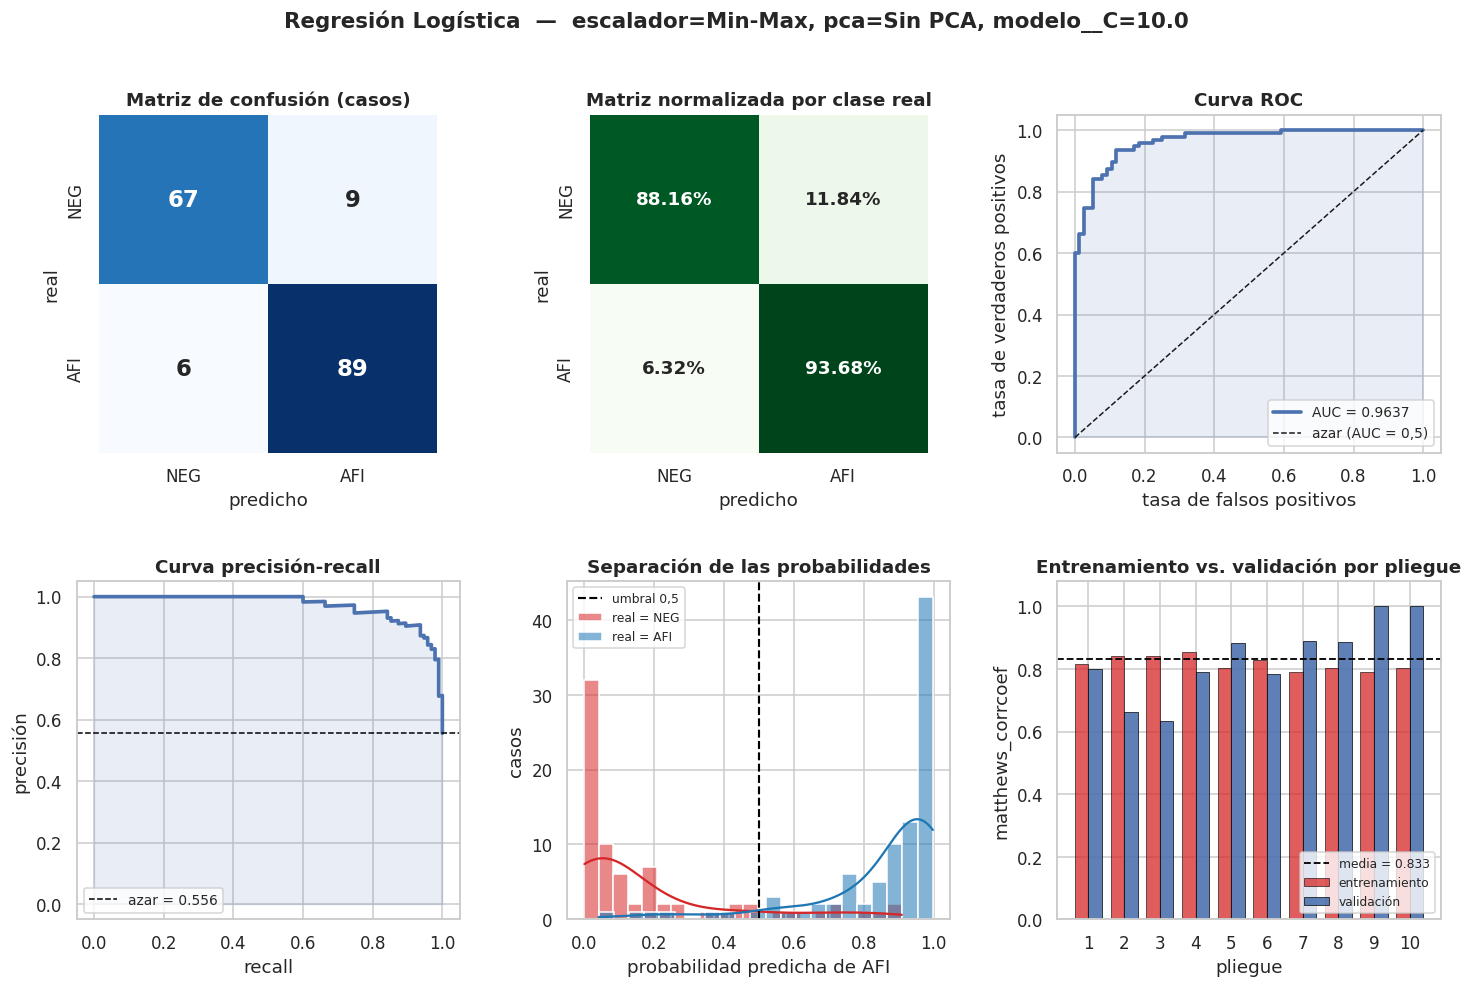


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 1


In [32]:
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", LogisticRegression(max_iter=1000, random_state=SEMILLA)),
])

grilla = {
         "escalador": list(ESCALADORES.values()),
         "pca":       list(OPCIONES_PCA.values()),
         "modelo__C": [0.01, 0.1, 1, 10, 100],
}

resultado = evaluar_modelo("Regresión Logística",pipeline, grilla)

---
<a id="sec-11"></a>
# 11. SVM (Máquinas de Vectores de Soporte)

**Cómo funciona.** Busca el hiperplano que separa las dos clases dejando el margen más ancho
posible entre ambas — es decir, no cualquier frontera que separe los datos, sino la que queda lo
más lejos posible de los puntos más cercanos de cada clase (los "vectores de soporte", que son los
únicos puntos que terminan determinando dónde queda esa frontera). Cuando las clases no son
separables con un hiperplano, permite que algunos puntos queden del lado equivocado o dentro del
margen, penalizando cada violación — ese es el parámetro `C`. Y cuando la frontera natural entre
las clases no es lineal, el "kernel" proyecta los datos (sin calcularlo explícitamente) a un
espacio de más dimensiones donde sí lo sea.

**Fundamentos.** Es un clasificador de margen máximo: de todas las fronteras lineales posibles que
separan (o casi separan) las clases, elige la más robusta a nuevos datos, porque maximiza la
distancia a los puntos más cercanos. El "truco del kernel" permite trabajar como si los datos
estuvieran en un espacio transformado de muchas más dimensiones sin tener que calcular esa
transformación explícitamente — solo se necesita poder calcular el producto interno entre pares de
puntos en ese espacio, que es justamente lo que define cada kernel.

**Ventajas.** Suele funcionar muy bien incluso con relativamente pocos datos y muchas variables,
porque la frontera queda determinada solo por los vectores de soporte, no por todos los puntos. El
kernel RBF (gaussiano) le permite capturar fronteras curvas complejas sin tener que diseñarlas a
mano. Es, junto con la regresión logística, de los modelos con base teórica más sólida de los doce.

**Parámetros de ajuste.**

*  `C` — penalización por violar el margen (puntos mal clasificados o demasiado cerca de la
   frontera). Rango típico: positivo, en escala logarítmica entre 0,001 y 1.000; más chico permite
   más violaciones (frontera más "ancha" y suave), más grande las castiga más (frontera más
   ajustada a los datos, con más riesgo de sobreajuste). Acá se prueban `[0.01, 0.1, 1, 10, 100]`.
*  `kernel` — la familia de transformación usada para medir similitud entre puntos. Las más
   comunes son lineal (sin transformación; frontera recta) y RBF o gaussiano (fronteras curvas,
   suaves, de complejidad controlada por `gamma`); también existen polinomial y sigmoide. Acá se
   prueban `["linear", "rbf"]`.
*  `gamma` — solo aplica al kernel RBF: qué tan lejos llega la influencia de un solo punto de
   entrenamiento. Valores chicos dan fronteras más suaves y globales; valores grandes, fronteras
   más ajustadas y locales (más riesgo de sobreajuste). Rango típico: positivo, en escala
   logarítmica entre 0,0001 y 10, o los valores automáticos `"scale"`/`"auto"` que lo calculan a
   partir de la varianza de los datos. Acá se prueban `["scale", 0.01, 0.1, 1]`.
*  `probability` — se fija en `True` (no se incluye en la grilla) porque el cuaderno necesita
   probabilidades, no solo la clase predicha, para calcular ROC-AUC y las curvas del punto 8.3;
   SVM no las produce naturalmente, así que las estima con un paso adicional de calibración.


  BÚSQUEDA — SVM
  Parámetros variados    : ['escalador', 'pca', 'modelo__C', 'modelo__kernel', 'modelo__gamma']
  Combinaciones evaluadas: 360   (ajustes totales: 3600)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__C,modelo__kernel,modelo__gamma,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Z-score,PCA-6,1.0000,rbf,0.0100,0.8134,0.8327,0.1179,0.0373,-0.0193,0.9077,0.9124,0.0600,0.0087
1,Z-score,PCA-7,1.0000,rbf,0.0100,0.8134,0.8327,0.1179,0.0373,-0.0193,0.9077,0.9124,0.0600,0.0095
2,Z-score,Sin PCA,1.0000,rbf,0.0100,0.8134,0.8327,0.1179,0.0373,-0.0193,0.9077,0.9124,0.0600,0.0080
3,Z-score,PCA-6,0.1000,linear,1,0.8133,0.8327,0.1179,0.0373,-0.0193,0.9077,0.9124,0.0600,0.0076
4,Z-score,PCA-7,0.1000,linear,1,0.8133,0.8327,0.1179,0.0373,-0.0193,0.9077,0.9124,0.0600,0.0073
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,Sin escalar,Sin PCA,0.0100,rbf,1,0.0000,0.0000,0.0000,0.0000,0.0000,0.5556,0.5556,0.0277,0.0076
356,Sin escalar,Sin PCA,0.0100,linear,1,0.0000,0.0000,0.0000,0.0000,0.0000,0.5556,0.5556,0.0277,0.0072
357,Sin escalar,PCA-7,0.0100,linear,1,0.0000,0.0000,0.0000,0.0000,0.0000,0.5556,0.5556,0.0277,0.0069
358,Z-score,Sin PCA,0.0100,rbf,1,0.0000,0.0000,0.0000,0.0000,0.0000,0.5556,0.5556,0.0277,0.0180


  Máximo bruto (matthews_corrcoef = 0.8327): {'escalador': 'Sin escalar', 'pca': 'Sin PCA', 'modelo__C': np.float64(1.0), 'modelo__kernel': 'rbf', 'modelo__gamma': 1}
      cota inferior: 0.7954
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8327): {'escalador': 'Sin escalar', 'pca': 'Sin PCA', 'modelo__C': np.float64(1.0), 'modelo__kernel': 'rbf', 'modelo__gamma': 1}
      cota inferior: 0.7954
  Es la misma combinación que el máximo bruto.
  SVM  —  escalador=Sin escalar, pca=Sin PCA, modelo__C=1.0, modelo__kernel=rbf, modelo__gamma=1
    Rendimiento general
      Accuracy               0.9123
    Clase positiva (AFI)
      Precisión              0.9082
      Recall                 0.9368
      F1-score               0.9223
    Promediadas entre clases
      Precisión macro        0.9130
      F1 macro               0.9108
    Independiente del umbral
      ROC-AUC                0.9589

  REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

  

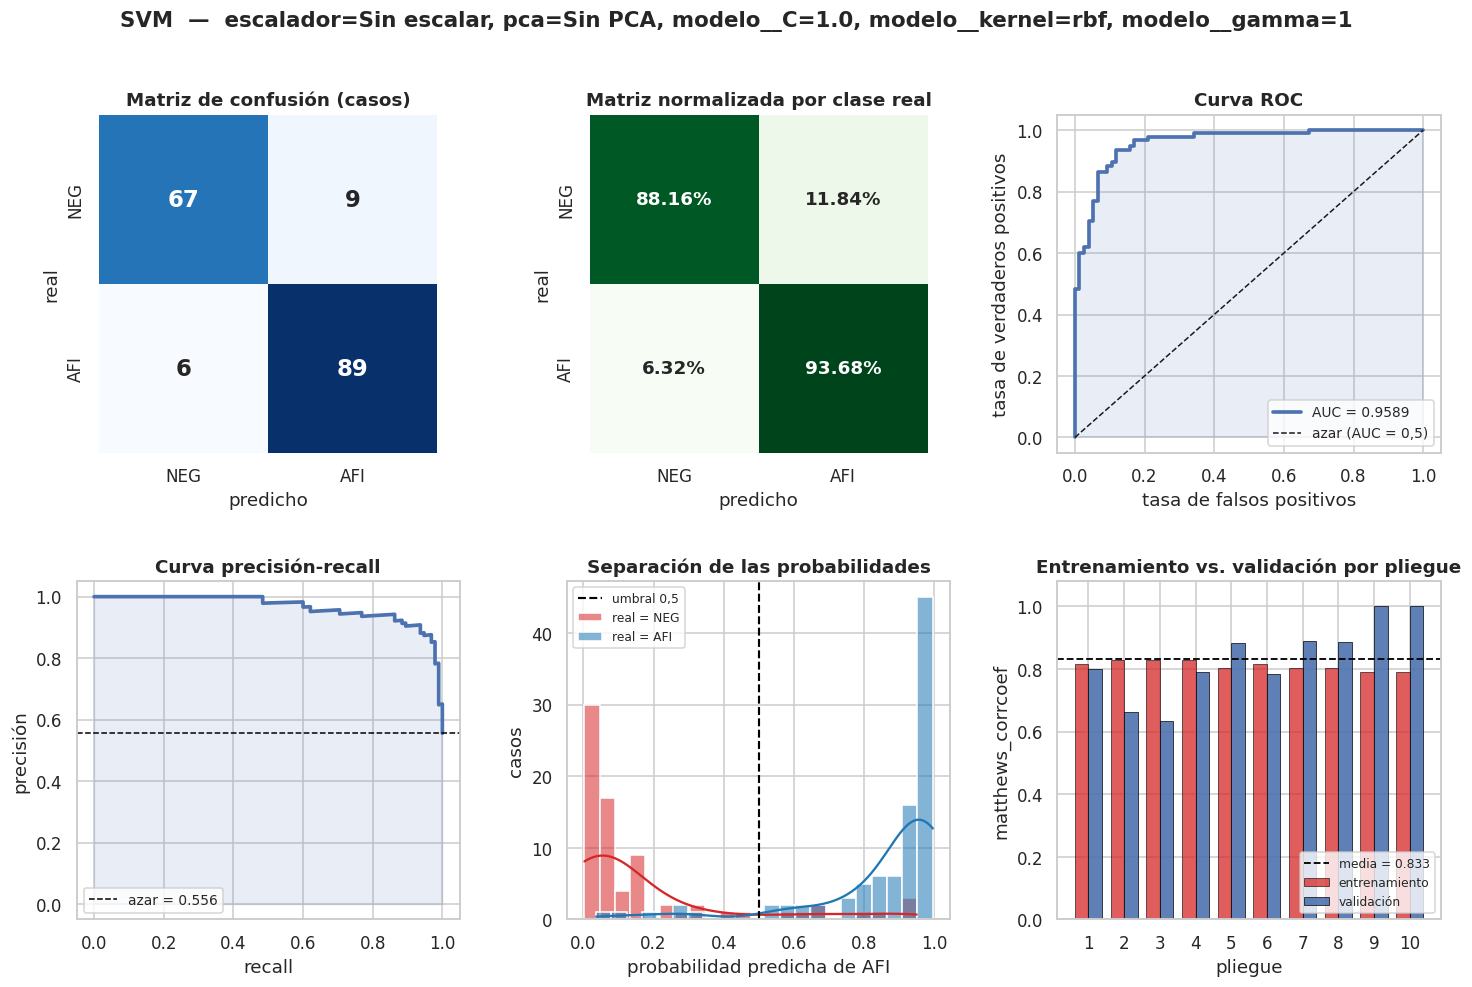


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 3


In [34]:
from sklearn.svm import SVC

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", SVC(probability=True, random_state=SEMILLA)),
])

grilla = {
             "escalador":     list(ESCALADORES.values()),
             "pca":           list(OPCIONES_PCA.values()),
             "modelo__C":      [0.01, 0.1, 1, 10, 100],
             "modelo__kernel": ["linear", "rbf"],
             "modelo__gamma":  ["scale", 0.01, 0.1, 1],
}

resultado_svm = evaluar_modelo("SVM", pipeline, grilla)

---
<a id="sec-12"></a>
# 12. K-Vecinos (KNN)

**Cómo funciona.** No ajusta ningún parámetro durante el entrenamiento: simplemente memoriza
todos los datos. Para clasificar un punto nuevo, busca los `k` puntos de entrenamiento más
cercanos (normalmente por distancia euclídea) y le asigna la clase mayoritaria entre esos vecinos
— o, si se pondera por distancia, los vecinos más cercanos pesan más que los más lejanos.

**Fundamentos.** Es el ejemplo más directo de aprendizaje "basado en instancias" (o "perezoso"):
en vez de resumir los datos de entrenamiento en unos pocos parámetros (como los pesos de una
regresión), toda la "memoria" del modelo son los datos mismos, y la predicción se calcula recién
en el momento de predecir. Asume que puntos cercanos en el espacio de las variables tienden a
tener la misma clase — por eso es tan sensible a la escala: sin escalar, una variable con rango
mucho más grande domina por completo el cálculo de distancia.

**Ventajas.** Es conceptualmente el más simple de los doce — no hay nada que "entender" del
modelo más allá de la noción de cercanía—, y puede capturar fronteras de decisión de forma
arbitrariamente irregular, sin asumir ninguna forma particular (lineal, por ejemplo) para la
relación entre las variables y la clase.

**Parámetros de ajuste.**

*  `n_neighbors` (`k`) — cantidad de vecinos que se consultan para cada predicción. Rango típico:
   enteros positivos, usualmente entre 3 y 30 — valores chicos dan fronteras muy irregulares y
   sensibles al ruido (riesgo de sobreajuste); valores grandes, fronteras más suaves pero que
   pueden perder detalle (riesgo de subajuste) y, en clases desbalanceadas, sesgarse hacia la
   clase mayoritaria. Acá se prueban `[3, 5, 7, 11, 15, 21]`.
*  `weights` — cómo pesa cada vecino en la votación. `"uniform"` le da el mismo peso a los `k`
   vecinos; `"distance"` pesa más a los más cercanos. Acá se prueban ambas.
*  Escalador y PCA — igual que en regresión logística, son parte de la grilla porque la distancia
   entre puntos (de la que depende todo el modelo) cambia completamente según la escala de cada
   variable.


  BÚSQUEDA — K-Vecinos
  Parámetros variados    : ['escalador', 'pca', 'modelo__n_neighbors', 'modelo__weights']
  Combinaciones evaluadas: 108   (ajustes totales: 1080)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__n_neighbors,modelo__weights,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Sin escalar,Sin PCA,15,uniform,0.8170,0.8019,0.1203,0.0381,0.0151,0.9097,0.9007,0.0590,0.0040
1,Sin escalar,PCA-7,15,uniform,0.8170,0.8019,0.1203,0.0381,0.0151,0.9097,0.9007,0.0590,0.0050
2,Sin escalar,PCA-6,15,uniform,0.8170,0.8019,0.1203,0.0381,0.0151,0.9097,0.9007,0.0590,0.0048
3,Sin escalar,PCA-6,5,uniform,0.8241,0.7940,0.1322,0.0418,0.0301,0.9129,0.8948,0.0633,0.0118
4,Sin escalar,PCA-7,5,distance,1.0000,0.7940,0.1322,0.0418,0.2060,1.0000,0.8948,0.0633,0.0036
...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,Z-score,Sin PCA,15,uniform,0.7816,0.7310,0.1623,0.0513,0.0506,0.8921,0.8654,0.0793,0.0057
104,Z-score,Sin PCA,15,distance,1.0000,0.7310,0.1623,0.0513,0.2690,1.0000,0.8654,0.0793,0.0063
105,Z-score,PCA-6,15,uniform,0.7816,0.7310,0.1623,0.0513,0.0506,0.8921,0.8654,0.0793,0.0069
106,Z-score,PCA-7,15,distance,1.0000,0.7310,0.1623,0.0513,0.2690,1.0000,0.8654,0.0793,0.0078


  Máximo bruto (matthews_corrcoef = 0.8019): {'escalador': 'Sin escalar', 'pca': 'Sin PCA', 'modelo__n_neighbors': np.int64(15), 'modelo__weights': 'uniform'}
      cota inferior: 0.7639
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8019): {'escalador': 'Sin escalar', 'pca': 'Sin PCA', 'modelo__n_neighbors': np.int64(15), 'modelo__weights': 'uniform'}
      cota inferior: 0.7639
  Es la misma combinación que el máximo bruto.
  K-VECINOS  —  escalador=Sin escalar, pca=Sin PCA, modelo__n_neighbors=15, modelo__weights=uniform
    Rendimiento general
      Accuracy               0.9006
    Clase positiva (AFI)
      Precisión              0.9062
      Recall                 0.9158
      F1-score               0.9110
    Promediadas entre clases
      Precisión macro        0.8998
      F1 macro               0.8992
    Independiente del umbral
      ROC-AUC                0.9481

  REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     NEG (0)   

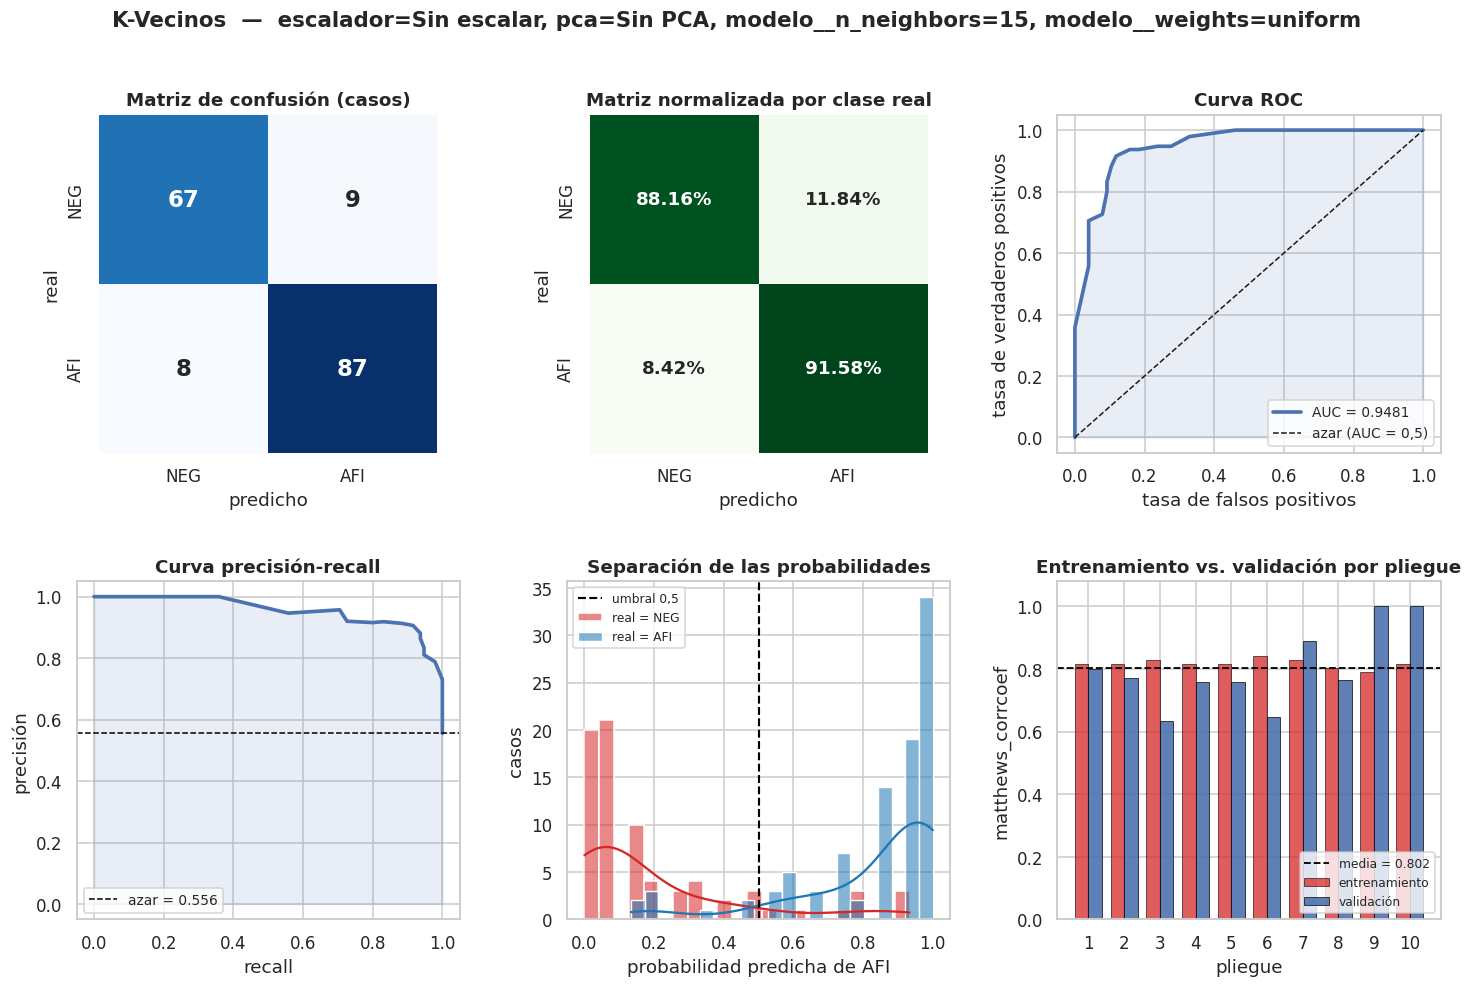


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 4


In [35]:
from sklearn.neighbors import KNeighborsClassifier

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", KNeighborsClassifier()),
])

grilla = {
         "escalador":          list(ESCALADORES.values()),
         "pca":                list(OPCIONES_PCA.values()),
         "modelo__n_neighbors": [3, 5, 7, 11, 15, 21],
         "modelo__weights":     ["uniform", "distance"],
}

resultado = evaluar_modelo("K-Vecinos", pipeline, grilla)

---
<a id="sec-13"></a>
# 13. Árbol de Decisión

**Cómo funciona.** Construye una secuencia de preguntas binarias sobre una variable a la vez (por
ejemplo, "¿la variable X es mayor que 3,2?"), elegidas de forma que cada pregunta separe lo mejor
posible las clases en los datos que llegan a ese punto. El resultado es un árbol: se empieza en la
raíz y se va bajando según las respuestas, hasta llegar a una hoja, que asigna la clase mayoritaria
de los datos de entrenamiento que terminaron ahí.

**Fundamentos.** En cada nodo, el algoritmo evalúa todas las variables y todos los puntos de corte
posibles, y elige la combinación que más reduce la "impureza" de las dos particiones resultantes
—medida con el índice Gini o con la entropía—, es decir, la que deja cada partición lo más
homogénea posible en cuanto a clase. Es un proceso voraz: decide la mejor pregunta en cada paso
sin mirar hacia adelante, por lo que no garantiza el árbol globalmente óptimo, pero sí uno
razonable y rápido de construir.

**Ventajas.** No necesita que las variables estén escaladas (las preguntas son del tipo
"mayor que", invariantes a cualquier transformación que preserve el orden), captura relaciones no
lineales e interacciones entre variables sin que haya que especificarlas, y su estructura se puede
dibujar y leer directamente — es, junto con la regresión logística, de los pocos modelos de este
cuaderno que un no especialista puede interpretar mirando el modelo mismo. También es la base
conceptual de Random Forest, Gradient Boosting, AdaBoost y HistGradientBoosting (puntos 14, 15, 19
y 21): los cuatro son, en esencia, muchos árboles combinados.

**Parámetros de ajuste.**

*  `max_depth` — profundidad máxima del árbol. Rango típico: `None` (sin límite, hasta que las
   hojas queden puras o no se pueda dividir más) o un entero entre 2 y 20; sin límite, un árbol de
   decisión tiende a sobreajustar severamente. Acá se prueban `[None, 3, 5, 7, 10]`.
*  `min_samples_leaf` — cantidad mínima de datos que debe tener una hoja para que esa división se
   permita. Rango típico: entero entre 1 y varias decenas; valores más altos fuerzan hojas más
   grandes y generalizables (menos sobreajuste). Acá se prueban `[1, 5, 10, 20]`.
*  `criterion` — la medida de impureza usada para decidir cada corte: `"gini"` (índice Gini) o
   `"entropy"` (entropía de información); en la práctica suelen dar árboles muy parecidos. Acá se
   prueban ambas.


  BÚSQUEDA — Árbol de Decisión
  Parámetros variados    : ['escalador', 'pca', 'modelo__max_depth', 'modelo__min_samples_leaf', 'modelo__criterion']
  Combinaciones evaluadas: 360   (ajustes totales: 3600)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__max_depth,modelo__min_samples_leaf,modelo__criterion,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Sin escalar,PCA-6,3,20,entropy,0.8299,0.8488,0.1147,0.0363,-0.0189,0.9149,0.9186,0.0641,0.0043
1,Sin escalar,PCA-7,Sin escalar,20,entropy,0.8299,0.8488,0.1147,0.0363,-0.0189,0.9149,0.9186,0.0641,0.0042
2,Sin escalar,PCA-6,Sin escalar,20,entropy,0.8299,0.8488,0.1147,0.0363,-0.0189,0.9149,0.9186,0.0641,0.0043
3,Sin escalar,PCA-7,3,20,entropy,0.8299,0.8488,0.1147,0.0363,-0.0189,0.9149,0.9186,0.0641,0.0047
4,Sin escalar,PCA-7,7,20,entropy,0.8299,0.8488,0.1147,0.0363,-0.0189,0.9149,0.9186,0.0641,0.0042
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,Z-score,Sin PCA,7,20,gini,0.7004,0.5794,0.1393,0.0440,0.1209,0.8447,0.7778,0.0779,0.0078
356,Sin escalar,Sin PCA,7,20,gini,0.7004,0.5794,0.1393,0.0440,0.1209,0.8447,0.7778,0.0779,0.0049
357,Min-Max,Sin PCA,3,10,entropy,0.7614,0.5737,0.1420,0.0449,0.1878,0.8759,0.7781,0.0767,0.0075
358,Sin escalar,Sin PCA,3,10,entropy,0.7614,0.5737,0.1420,0.0449,0.1878,0.8759,0.7781,0.0767,0.0036


  Máximo bruto (matthews_corrcoef = 0.8488): {'escalador': 'Sin escalar', 'pca': 'PCA-7', 'modelo__max_depth': 'Sin escalar', 'modelo__min_samples_leaf': np.int64(20), 'modelo__criterion': 'entropy'}
      cota inferior: 0.8125
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8488): {'escalador': 'Sin escalar', 'pca': 'PCA-7', 'modelo__max_depth': 'Sin escalar', 'modelo__min_samples_leaf': np.int64(20), 'modelo__criterion': 'entropy'}
      cota inferior: 0.8125
  Es la misma combinación que el máximo bruto.
  ÁRBOL DE DECISIÓN  —  escalador=Sin escalar, pca=PCA-7, modelo__max_depth=Sin escalar, modelo__min_samples_leaf=20, modelo__criterion=entropy
    Rendimiento general
      Accuracy               0.9181
    Clase positiva (AFI)
      Precisión              0.9451
      Recall                 0.9053
      F1-score               0.9247
    Promediadas entre clases
      Precisión macro        0.9163
      F1 macro               0.9175
    Independiente del umbral
      RO

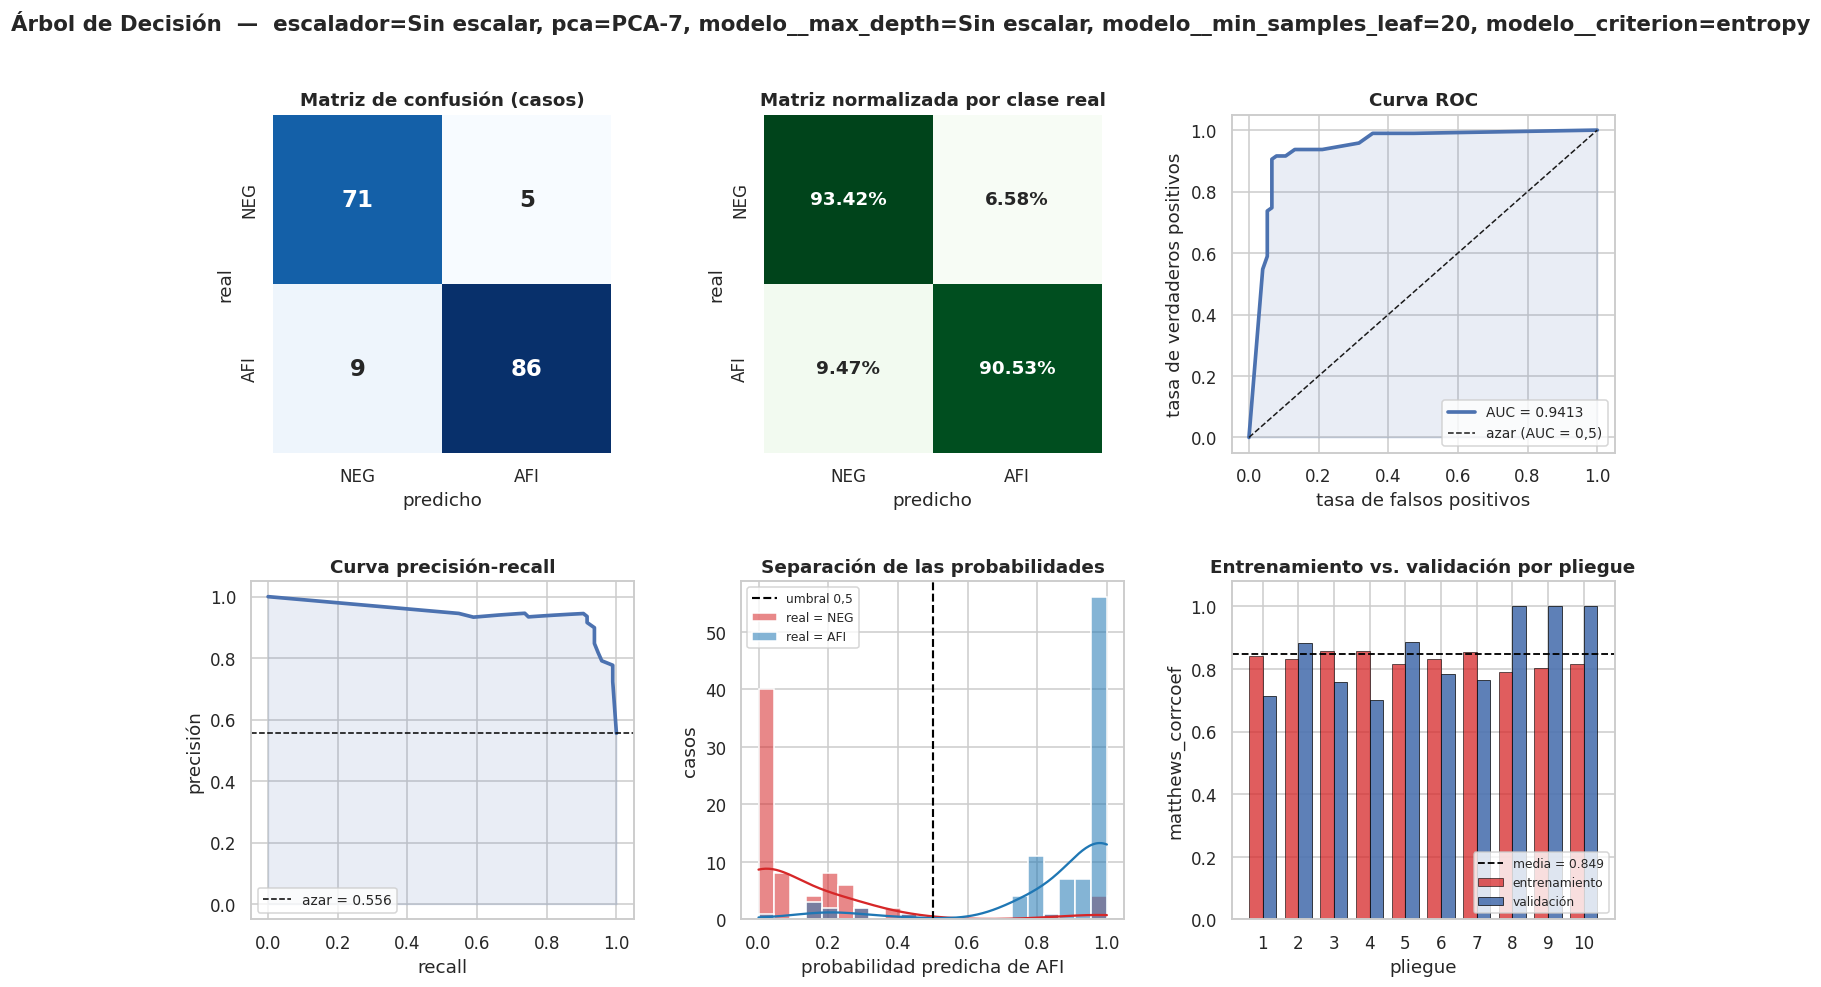


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 5


In [36]:
from sklearn.tree import DecisionTreeClassifier

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", DecisionTreeClassifier(random_state=SEMILLA)),
])

grilla = {
         "escalador":              list(ESCALADORES.values()),
         "pca":                    list(OPCIONES_PCA.values()),
         "modelo__max_depth":      [None, 3, 5, 7, 10],
         "modelo__min_samples_leaf": [1, 5, 10, 20],
         "modelo__criterion":      ["gini", "entropy"],
}

resultado = evaluar_modelo("Árbol de Decisión", pipeline, grilla)

---
<a id="sec-14"></a>
# 14. Random Forest

**Cómo funciona.** Entrena muchos árboles de decisión (punto 13) independientes entre sí, y
combina sus votos: la clase predicha es la que elige la mayoría de los árboles. Cada árbol se
entrena con dos fuentes de aleatoriedad para que no sean todos iguales: una muestra con reemplazo
de los datos de entrenamiento (bootstrap) distinta para cada árbol, y, en cada corte, solo se le
permite elegir entre un subconjunto aleatorio de las variables (no todas).

**Fundamentos.** Es un método de "ensamble por bagging" (bootstrap aggregating): promediar
(o votar) muchos modelos con alta varianza pero entrenados sobre datos ligeramente distintos
reduce esa varianza sin aumentar el sesgo, porque los errores de cada árbol individual —que
tienden a sobreajustar— se cancelan parcialmente entre sí al promediarlos. Cuantos más árboles, más
estable el resultado (con retornos decrecientes); la aleatoriedad en las variables disponibles en
cada corte además hace que los árboles sean menos parecidos entre sí, lo cual ayuda a que ese
cancelamiento de errores funcione mejor.

**Ventajas.** Suele dar muy buen resultado con poco ajuste fino, es bastante robusto a variables
irrelevantes o ruidosas (se diluyen en el promedio), no necesita que las variables estén
escaladas (igual que un árbol individual), y es mucho menos propenso a sobreajustar que un árbol
de decisión solo.

**Parámetros de ajuste.**

*  `n_estimators` — cantidad de árboles del bosque. Rango típico: entero positivo, usualmente entre
   100 y varios miles; más árboles casi nunca empeora el resultado, solo cuesta más tiempo de
   cómputo (es el parámetro con menor riesgo de sobreajuste de toda la grilla). Acá se prueban
   `[100, 400]`.
*  `max_depth` — profundidad máxima de cada árbol individual. Rango típico: `None` o entero entre 3
   y 30; en un bosque, árboles más profundos suelen tolerarse mejor que en un árbol solo, porque el
   promedio entre muchos compensa el sobreajuste individual. Acá se prueban `[None, 5, 10]`.
*  `min_samples_leaf` — igual que en el árbol de decisión individual, el tamaño mínimo de una hoja.
   Acá se prueban `[1, 5, 10]`.
*  Nota: a diferencia del resto de los modelos de este cuaderno, el pipeline de Random Forest no
   incluye PCA — se retiró deliberadamente de la grilla para acortar el tiempo de búsqueda, ya que
   un bosque de árboles no se beneficia de la reducción de dimensionalidad del mismo modo que un
   modelo lineal o basado en distancias.


  BÚSQUEDA — Random Forest
  Parámetros variados    : ['escalador', 'modelo__n_estimators', 'modelo__max_depth', 'modelo__min_samples_leaf']
  Combinaciones evaluadas: 54   (ajustes totales: 540)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,modelo__n_estimators,modelo__max_depth,modelo__min_samples_leaf,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Sin escalar,400,Sin escalar,10,0.8922,0.8309,0.1189,0.0376,0.0613,0.9467,0.9124,0.0600,0.7451
1,Sin escalar,400,5,10,0.8922,0.8309,0.1189,0.0376,0.0613,0.9467,0.9124,0.0600,0.7496
2,Sin escalar,400,10,10,0.8922,0.8309,0.1189,0.0376,0.0613,0.9467,0.9124,0.0600,0.6639
3,Min-Max,400,10,10,0.8922,0.8309,0.1189,0.0376,0.0613,0.9467,0.9124,0.0600,0.7402
4,Min-Max,400,5,10,0.8922,0.8309,0.1189,0.0376,0.0613,0.9467,0.9124,0.0600,0.6551
5,Min-Max,400,Sin escalar,10,0.8922,0.8309,0.1189,0.0376,0.0613,0.9467,0.9124,0.0600,0.6192
6,Z-score,400,Sin escalar,10,0.8922,0.8309,0.1189,0.0376,0.0613,0.9467,0.9124,0.0600,0.7533
7,Z-score,400,5,10,0.8922,0.8309,0.1189,0.0376,0.0613,0.9467,0.9124,0.0600,0.7286
8,Z-score,400,10,10,0.8922,0.8309,0.1189,0.0376,0.0613,0.9467,0.9124,0.0600,0.6131
9,Min-Max,400,10,5,0.9225,0.8209,0.1557,0.0492,0.1017,0.9617,0.9069,0.0788,0.7526


  Máximo bruto (matthews_corrcoef = 0.8309): {'escalador': 'Sin escalar', 'modelo__n_estimators': np.int64(400), 'modelo__max_depth': 'Sin escalar', 'modelo__min_samples_leaf': np.int64(10)}
      cota inferior: 0.7933
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8309): {'escalador': 'Sin escalar', 'modelo__n_estimators': np.int64(400), 'modelo__max_depth': 'Sin escalar', 'modelo__min_samples_leaf': np.int64(10)}
      cota inferior: 0.7933
  Es la misma combinación que el máximo bruto.
  RANDOM FOREST  —  escalador=Sin escalar, modelo__n_estimators=400, modelo__max_depth=Sin escalar, modelo__min_samples_leaf=10
    Rendimiento general
      Accuracy               0.9123
    Clase positiva (AFI)
      Precisión              0.9255
      Recall                 0.9158
      F1-score               0.9206
    Promediadas entre clases
      Precisión macro        0.9108
      F1 macro               0.9113
    Independiente del umbral
      ROC-AUC                0.9575

  REP

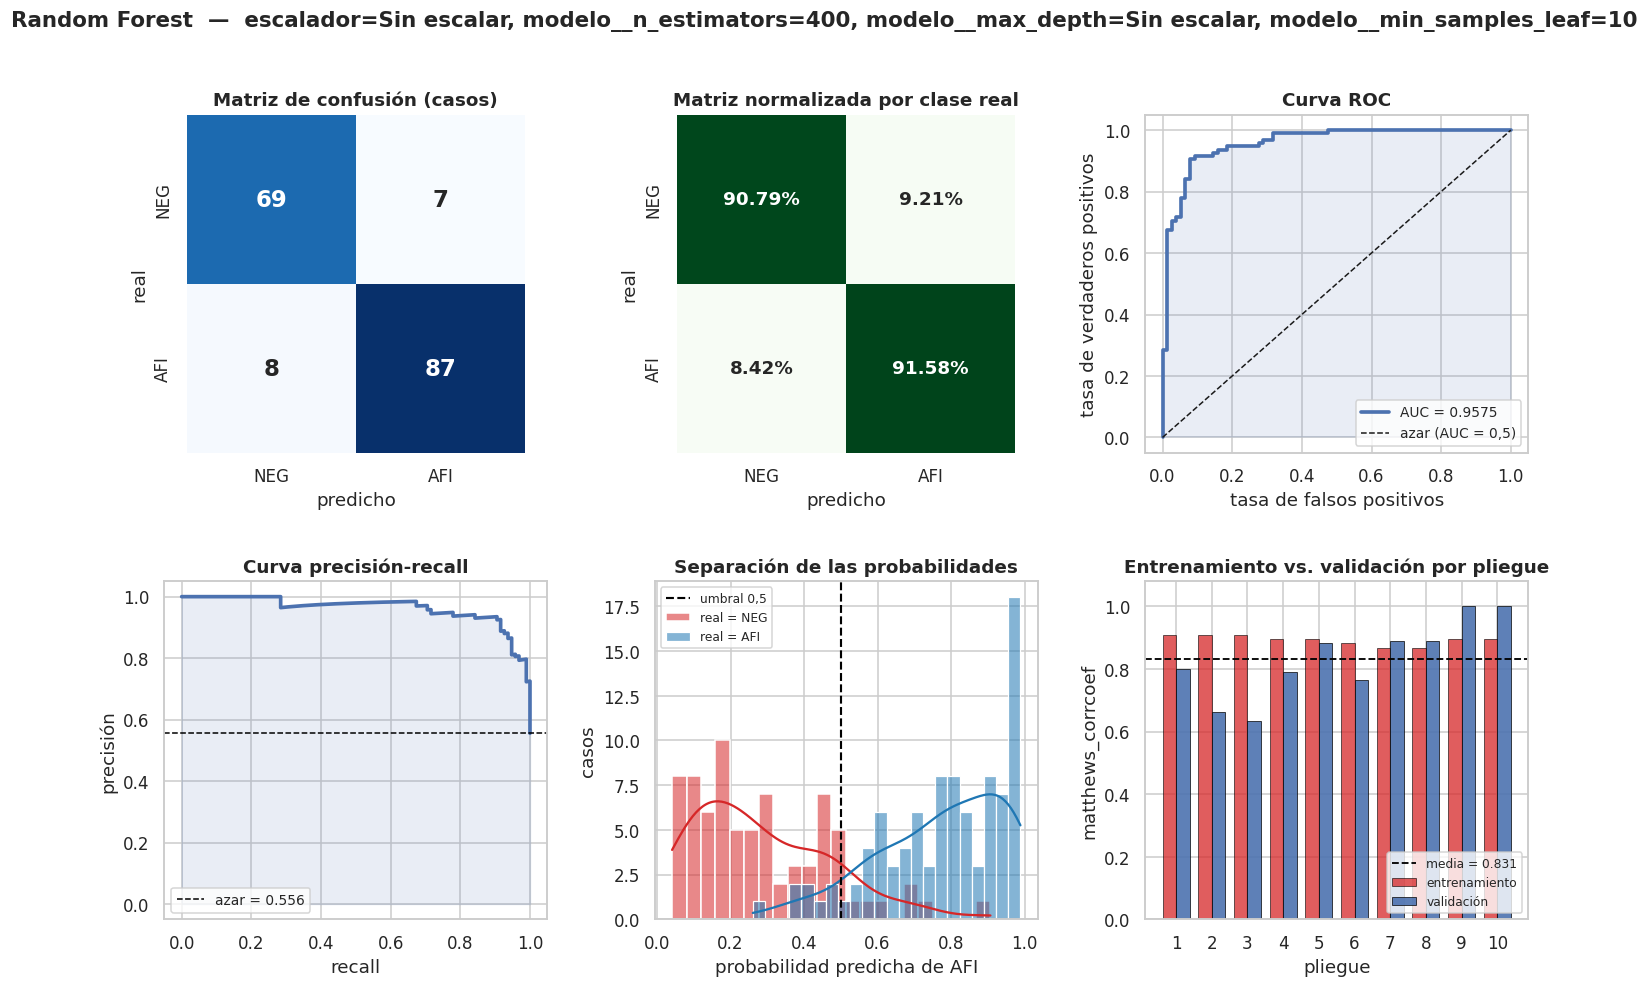


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 6


In [37]:
from sklearn.ensemble import RandomForestClassifier

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", RandomForestClassifier(random_state=SEMILLA)),
])

grilla = {
         "escalador":                list(ESCALADORES.values()),
         "modelo__n_estimators":     [100, 400],
         "modelo__max_depth":        [None, 5, 10],
         "modelo__min_samples_leaf": [1, 5, 10],
}

resultado = evaluar_modelo("Random Forest", pipeline, grilla)

---
<a id="sec-15"></a>
# 15. Gradient Boosting

**Cómo funciona.** También combina muchos árboles, pero no de forma independiente como Random
Forest: los entrena uno detrás de otro, y cada árbol nuevo se entrena específicamente para corregir
los errores que quedaron después de los árboles anteriores. El resultado final es la suma
(ponderada por `learning_rate`) de las predicciones de todos los árboles de la secuencia.

**Fundamentos.** Es un método de "boosting": en lugar de promediar modelos independientes
(bagging), ajusta cada nuevo árbol al gradiente del error que cometen los árboles anteriores
—es decir, cada árbol aprende a predecir en qué dirección y cuánto hay que corregir la predicción
acumulada hasta ese punto para reducir el error—. Esto hace que la secuencia se concentre, cada vez
más, en los casos difíciles que los árboles anteriores todavía no clasifican bien.

**Ventajas.** Suele lograr el mejor desempeño puro entre los modelos basados en árboles,
precisamente porque cada árbol se enfoca en corregir lo que falta. A cambio, es más sensible a mal
ajustado que Random Forest (si se le permite seguir corrigiendo demasiado tiempo, termina
memorizando el ruido de los datos de entrenamiento) y más lento de entrenar, porque los árboles no
se pueden construir en paralelo.

**Parámetros de ajuste.**

*  `n_estimators` — cantidad de árboles en la secuencia. Rango típico: entero positivo, entre 50 y
   varios miles; a diferencia de Random Forest, acá sí hay riesgo real de sobreajuste si es
   demasiado alto, en particular combinado con un `learning_rate` alto. Acá se prueban
   `[100, 200]`.
*  `learning_rate` — cuánto pesa la corrección de cada árbol nuevo sobre la predicción acumulada.
   Rango típico: positivo, usualmente entre 0,001 y 0,3; valores chicos necesitan más árboles pero
   generalizan mejor, valores grandes convergen más rápido pero con más riesgo de sobreajuste. Acá
   se prueban `[0.01, 0.1, 0.2]`.
*  `max_depth` — profundidad de cada árbol individual de la secuencia. A diferencia de Random
   Forest, en boosting conviene que cada árbol sea chico (un "aprendiz débil"), porque la fuerza
   del método está en la secuencia, no en árboles individuales complejos. Rango típico: entero
   entre 1 y 8. Acá se prueban `[2, 3, 4]`.


  BÚSQUEDA — Gradient Boosting
  Parámetros variados    : ['escalador', 'pca', 'modelo__n_estimators', 'modelo__learning_rate', 'modelo__max_depth']
  Combinaciones evaluadas: 162   (ajustes totales: 1620)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__n_estimators,modelo__learning_rate,modelo__max_depth,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Sin escalar,PCA-6,100,0.0100,2,0.8624,0.8483,0.1146,0.0362,0.0141,0.9318,0.9186,0.0641,0.1275
1,Sin escalar,PCA-7,100,0.0100,2,0.8648,0.8372,0.1161,0.0367,0.0276,0.9331,0.9127,0.0645,0.1314
2,Sin escalar,PCA-6,200,0.0100,2,0.8849,0.8261,0.1047,0.0331,0.0588,0.9428,0.9069,0.0587,0.2514
3,Sin escalar,PCA-7,200,0.0100,2,0.8863,0.8261,0.1047,0.0331,0.0602,0.9435,0.9069,0.0587,0.3352
4,Z-score,PCA-6,200,0.1000,2,1.0000,0.8241,0.1090,0.0345,0.1759,1.0000,0.9069,0.0587,0.2510
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,Sin escalar,Sin PCA,200,0.0100,4,0.9895,0.6978,0.1955,0.0618,0.2917,0.9948,0.8431,0.1019,0.4164
158,Min-Max,Sin PCA,200,0.0100,4,0.9895,0.6978,0.1955,0.0618,0.2917,0.9948,0.8431,0.1019,0.4198
159,Sin escalar,Sin PCA,100,0.0100,3,0.9220,0.6856,0.1718,0.0543,0.2364,0.9604,0.8373,0.0903,0.1694
160,Min-Max,Sin PCA,100,0.0100,3,0.9220,0.6856,0.1718,0.0543,0.2364,0.9604,0.8373,0.0903,0.1714


  Máximo bruto (matthews_corrcoef = 0.8483): {'escalador': 'Sin escalar', 'pca': 'PCA-6', 'modelo__n_estimators': np.int64(100), 'modelo__learning_rate': np.float64(0.01), 'modelo__max_depth': np.int64(2)}
      cota inferior: 0.8121
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8483): {'escalador': 'Sin escalar', 'pca': 'PCA-6', 'modelo__n_estimators': np.int64(100), 'modelo__learning_rate': np.float64(0.01), 'modelo__max_depth': np.int64(2)}
      cota inferior: 0.8121
  Es la misma combinación que el máximo bruto.
  GRADIENT BOOSTING  —  escalador=Sin escalar, pca=PCA-6, modelo__n_estimators=100, modelo__learning_rate=0.01, modelo__max_depth=2
    Rendimiento general
      Accuracy               0.9181
    Clase positiva (AFI)
      Precisión              0.9355
      Recall                 0.9158
      F1-score               0.9255
    Promediadas entre clases
      Precisión macro        0.9165
      F1 macro               0.9173
    Independiente del umbral
      RO

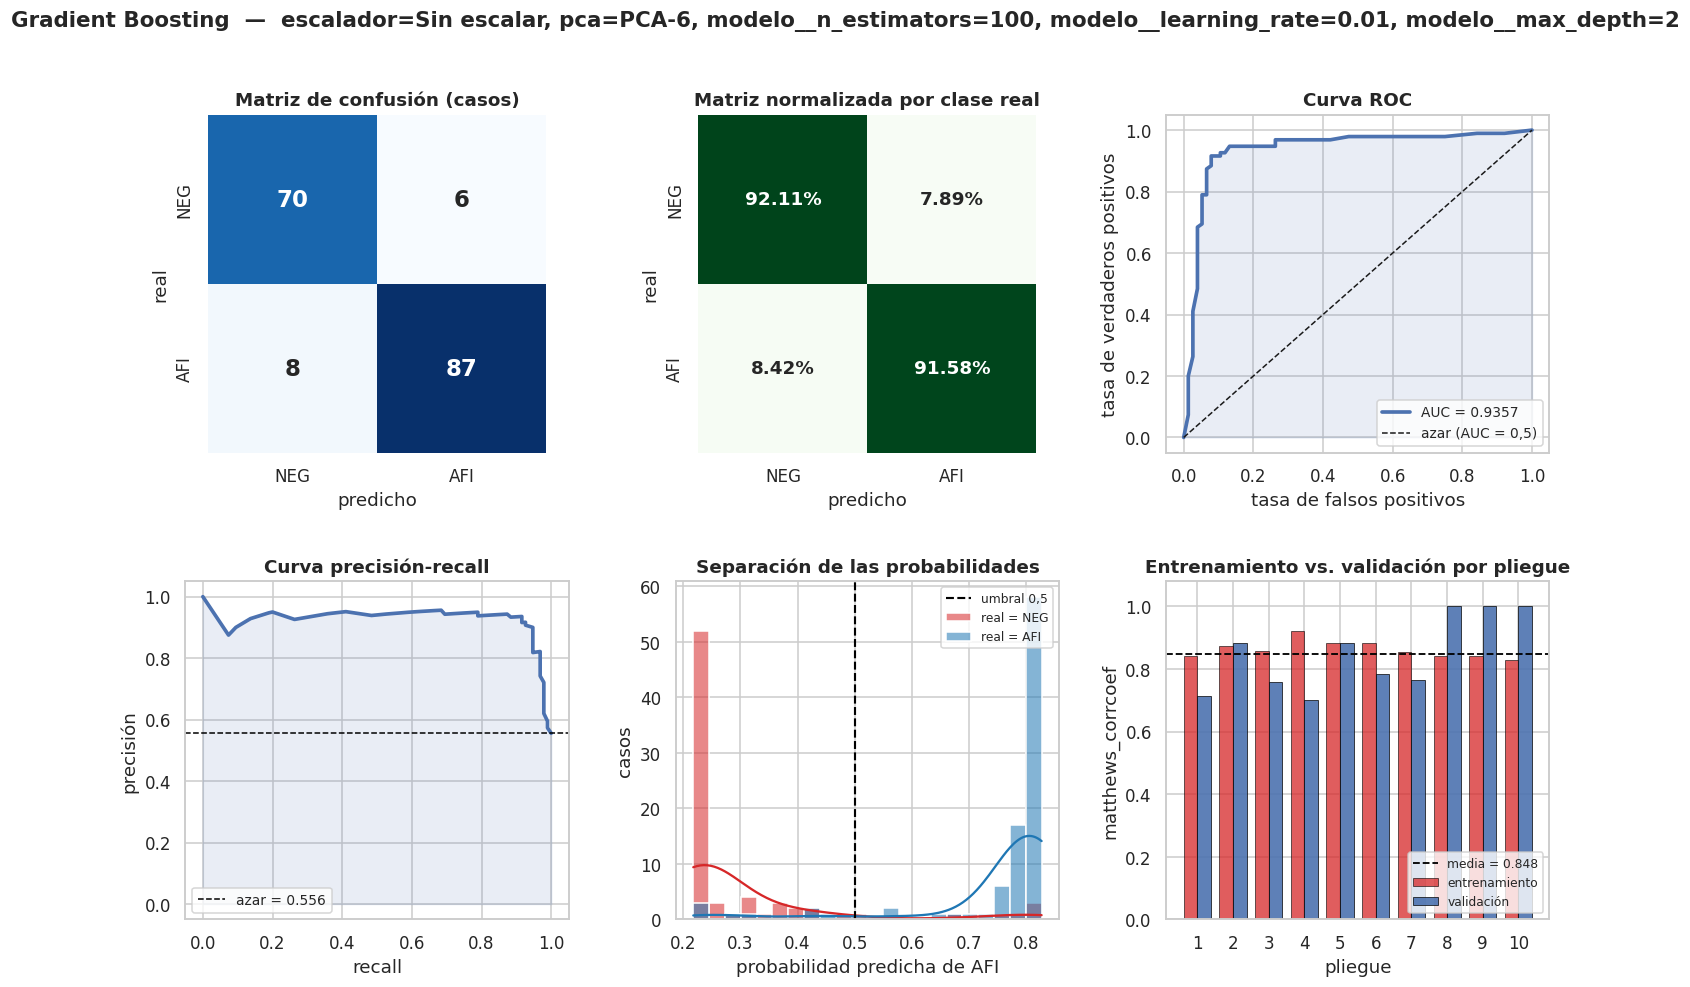


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 7


In [38]:
from sklearn.ensemble import GradientBoostingClassifier

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", GradientBoostingClassifier(random_state=SEMILLA)),
])

grilla = {
         "escalador":            list(ESCALADORES.values()),
         "pca":                  list(OPCIONES_PCA.values()),
         "modelo__n_estimators":  [100, 200],
         "modelo__learning_rate": [0.01, 0.1, 0.2],
         "modelo__max_depth":     [2, 3, 4],
}

resultado = evaluar_modelo("Gradient Boosting", pipeline, grilla)

---
<a id="sec-16"></a>
# 16. Naive Bayes

**Cómo funciona.** Calcula, para cada clase, la probabilidad de observar los valores de las
variables de un caso dado que pertenece a esa clase, asumiendo que todas las variables son
independientes entre sí dado la clase — una simplificación fuerte que le da el nombre ("naive",
ingenuo). En la variante usada acá (gaussiana), esa probabilidad para cada variable se modela con
una distribución normal, con media y varianza estimadas a partir de los datos de entrenamiento de
cada clase. Combinando esas probabilidades (vía el teorema de Bayes) con qué tan frecuente es cada
clase en los datos, se obtiene la probabilidad de cada clase dado el caso, y se predice la más
probable.

**Fundamentos.** Es una aplicación directa del teorema de Bayes: la probabilidad de la clase dado
los datos es proporcional a la probabilidad de los datos dado la clase, multiplicada por la
probabilidad previa de la clase. El supuesto de independencia entre variables (dado la clase) es
lo que hace que el cálculo sea trivial —se multiplican las probabilidades individuales de cada
variable en vez de tener que modelar su distribución conjunta—, aunque casi nunca se cumple
exactamente en datos reales.

**Ventajas.** Es extremadamente rápido de entrenar (no hay optimización iterativa: las medias y
varianzas se calculan directo de los datos) y suele funcionar razonablemente bien incluso cuando
el supuesto de independencia no se cumple del todo, en particular con pocos datos, donde modelos
más flexibles no tienen suficiente información para ajustar bien.

**Parámetros de ajuste.**

*  `var_smoothing` — una fracción muy chica que se suma a la varianza estimada de cada variable,
   para evitar divisiones por un número cercano a cero cuando una variable tiene varianza muy baja
   dentro de alguna clase. Rango típico: positivo y muy pequeño, usualmente entre 1e-12 y 1e-6. Acá
   se prueban `[1e-9, 1e-8, 1e-7]`. Es, de los doce modelos, el que tiene menos margen real de
   ajuste: casi todo el comportamiento del modelo queda determinado por los datos mismos, no por
   este parámetro.


  BÚSQUEDA — Naive Bayes
  Parámetros variados    : ['escalador', 'pca', 'modelo__var_smoothing']
  Combinaciones evaluadas: 27   (ajustes totales: 270)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__var_smoothing,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Min-Max,PCA-7,0.0000,0.8079,0.8193,0.1069,0.0338,-0.0115,0.9051,0.9065,0.0537,0.0046
1,Min-Max,PCA-7,0.0000,0.8079,0.8193,0.1069,0.0338,-0.0115,0.9051,0.9065,0.0537,0.0056
2,Min-Max,PCA-6,0.0000,0.8079,0.8193,0.1069,0.0338,-0.0115,0.9051,0.9065,0.0537,0.0046
3,Min-Max,PCA-7,0.0000,0.8079,0.8193,0.1069,0.0338,-0.0115,0.9051,0.9065,0.0537,0.0050
4,Min-Max,PCA-6,0.0000,0.8079,0.8193,0.1069,0.0338,-0.0115,0.9051,0.9065,0.0537,0.0049
5,Min-Max,PCA-6,0.0000,0.8079,0.8193,0.1069,0.0338,-0.0115,0.9051,0.9065,0.0537,0.0048
6,Min-Max,Sin PCA,0.0000,0.8050,0.8009,0.1646,0.0521,0.0042,0.9038,0.9007,0.0790,0.0041
7,Min-Max,Sin PCA,0.0000,0.8050,0.8009,0.1646,0.0521,0.0042,0.9038,0.9007,0.0790,0.0040
8,Sin escalar,Sin PCA,0.0000,0.8050,0.8009,0.1646,0.0521,0.0042,0.9038,0.9007,0.0790,0.0027
9,Sin escalar,Sin PCA,0.0000,0.8050,0.8009,0.1646,0.0521,0.0042,0.9038,0.9007,0.0790,0.0027


  Máximo bruto (matthews_corrcoef = 0.8193): {'escalador': 'Min-Max', 'pca': 'PCA-7', 'modelo__var_smoothing': np.float64(1e-09)}
      cota inferior: 0.7855
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8193): {'escalador': 'Min-Max', 'pca': 'PCA-7', 'modelo__var_smoothing': np.float64(1e-09)}
      cota inferior: 0.7855
  Es la misma combinación que el máximo bruto.
  NAIVE BAYES  —  escalador=Min-Max, pca=PCA-7, modelo__var_smoothing=1e-09
    Rendimiento general
      Accuracy               0.9064
    Clase positiva (AFI)
      Precisión              0.8990
      Recall                 0.9368
      F1-score               0.9175
    Promediadas entre clases
      Precisión macro        0.9078
      F1 macro               0.9047
    Independiente del umbral
      ROC-AUC                0.9435

  REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     NEG (0)     0.9167    0.8684    0.8919        76
     AFI (1)     0.8990    0.9368    0.9175

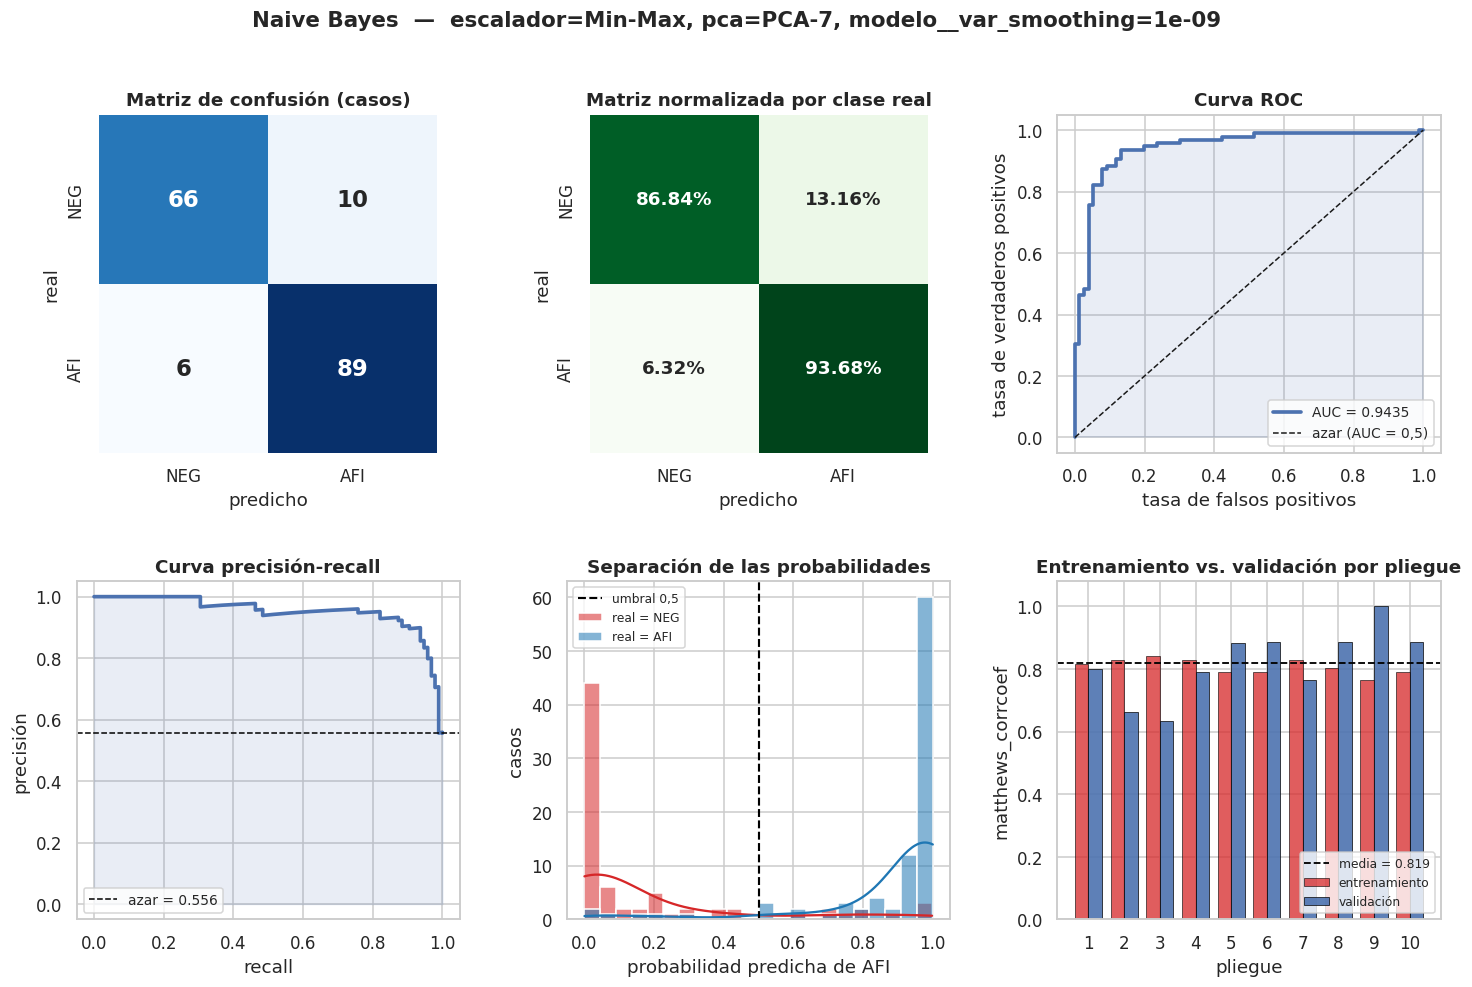


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 8


In [39]:
from sklearn.naive_bayes import GaussianNB

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", GaussianNB()),
])

grilla = {
         "escalador":        list(ESCALADORES.values()),
         "pca":              list(OPCIONES_PCA.values()),
         "modelo__var_smoothing": [1e-9, 1e-8, 1e-7],
}

resultado = evaluar_modelo("Naive Bayes", pipeline, grilla)

---
<a id="sec-17"></a>
# 17. Red Neuronal (MLP)

**Cómo funciona.** Un perceptrón multicapa encadena varias capas de neuronas: cada neurona
calcula una combinación lineal de las salidas de la capa anterior y le aplica una función de
activación no lineal. La primera capa recibe las variables predictoras, las capas intermedias
("ocultas") van transformando esa representación, y la última capa produce la probabilidad de
cada clase. Los pesos de todas las capas se ajustan juntos, mediante retropropagación del error y
descenso por gradiente, para minimizar el error de clasificación en los datos de entrenamiento.

**Fundamentos.** Cada combinación lineal seguida de una no linealidad es, en sí misma, parecida a
una regresión logística; lo que le da poder expresivo adicional es apilar varias de estas capas:
en teoría, una red con suficientes neuronas en una sola capa oculta puede aproximar cualquier
función continua (teorema de aproximación universal), aunque en la práctica varias capas más
chicas suelen aprender mejor que una sola capa muy ancha. A diferencia de los modelos basados en
árboles, acá no hay ninguna estructura de "preguntas"; todo el conocimiento queda codificado en los
pesos numéricos de las conexiones entre neuronas.

**Ventajas.** Puede aproximar relaciones muy complejas y no lineales entre las variables y la
clase, sin que haya que especificar esa forma funcional de antemano — a cambio de ser, de los doce
modelos, el menos interpretable (no hay una forma simple de explicar por qué predijo lo que
predijo) y el más sensible a la elección de hiperparámetros y a la escala de las variables.

**Parámetros de ajuste.**

*  `hidden_layer_sizes` — cantidad de capas ocultas y de neuronas en cada una. Rango típico:
   depende mucho del problema; para datasets chicos o medianos, una o dos capas de entre 10 y 200
   neuronas suele alcanzar. Acá se prueban `[(50,), (100,), (50, 25)]` — una capa de 50, una capa
   de 100, y dos capas (50 y luego 25).
*  `alpha` — fuerza de la regularización L2 sobre los pesos (penaliza pesos grandes, para evitar
   sobreajuste). Rango típico: positivo, en escala logarítmica entre 0,00001 y 1. Acá se prueban
   `[0.0001, 0.001, 0.01]`.
*  `learning_rate_init` — tamaño del paso inicial del descenso por gradiente. Rango típico:
   positivo, usualmente entre 0,0001 y 0,1; muy alto puede hacer que el entrenamiento no converja,
   muy bajo lo hace lento. Acá se prueban `[0.001, 0.01]`.
*  `max_iter` — tope de iteraciones de entrenamiento; se fija en 2.000 (no entra en la grilla) para
   darle margen suficiente a converger antes de evaluar los demás hiperparámetros.


  BÚSQUEDA — Red Neuronal (MLP)
  Parámetros variados    : ['escalador', 'pca', 'modelo__hidden_layer_sizes', 'modelo__alpha', 'modelo__learning_rate_init']
  Combinaciones evaluadas: 162   (ajustes totales: 1620)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__hidden_layer_sizes,modelo__alpha,modelo__learning_rate_init,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Sin escalar,Sin PCA,"(50,)",0.0001,0.0010,0.8171,0.8327,0.1179,0.0373,-0.0156,0.9097,0.9124,0.0600,0.2674
1,Sin escalar,Sin PCA,"(50,)",0.0010,0.0010,0.8171,0.8327,0.1179,0.0373,-0.0156,0.9097,0.9124,0.0600,0.2454
2,Min-Max,Sin PCA,"(50,)",0.0010,0.0010,0.8157,0.8327,0.1179,0.0373,-0.0170,0.9090,0.9124,0.0600,0.2041
3,Min-Max,Sin PCA,"(50,)",0.0100,0.0010,0.8144,0.8327,0.1179,0.0373,-0.0183,0.9084,0.9124,0.0600,0.2024
4,Min-Max,Sin PCA,"(50,)",0.0001,0.0010,0.8157,0.8327,0.1179,0.0373,-0.0170,0.9090,0.9124,0.0600,0.2035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,Min-Max,PCA-6,"(50,)",0.0001,0.0100,0.9829,0.6874,0.1945,0.0615,0.2955,0.9915,0.8431,0.0949,0.3006
158,Sin escalar,PCA-6,"(50, 25)",0.0010,0.0100,0.9698,0.6831,0.1906,0.0603,0.2867,0.9851,0.8369,0.0957,0.2432
159,Sin escalar,Sin PCA,"(50, 25)",0.0100,0.0100,0.9568,0.6806,0.1759,0.0556,0.2761,0.9786,0.8369,0.0881,0.4363
160,Sin escalar,Sin PCA,"(50, 25)",0.0001,0.0100,0.9505,0.6805,0.1906,0.0603,0.2700,0.9753,0.8369,0.0957,0.2916


  Máximo bruto (matthews_corrcoef = 0.8327): {'escalador': 'Sin escalar', 'pca': 'Sin PCA', 'modelo__hidden_layer_sizes': (50,), 'modelo__alpha': np.float64(0.0001), 'modelo__learning_rate_init': np.float64(0.001)}
      cota inferior: 0.7954
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8327): {'escalador': 'Sin escalar', 'pca': 'Sin PCA', 'modelo__hidden_layer_sizes': (50,), 'modelo__alpha': np.float64(0.0001), 'modelo__learning_rate_init': np.float64(0.001)}
      cota inferior: 0.7954
  Es la misma combinación que el máximo bruto.
  RED NEURONAL (MLP)  —  escalador=Sin escalar, pca=Sin PCA, modelo__hidden_layer_sizes=(50,), modelo__alpha=0.0001, modelo__learning_rate_init=0.001
    Rendimiento general
      Accuracy               0.9123
    Clase positiva (AFI)
      Precisión              0.9082
      Recall                 0.9368
      F1-score               0.9223
    Promediadas entre clases
      Precisión macro        0.9130
      F1 macro               0.9108
 

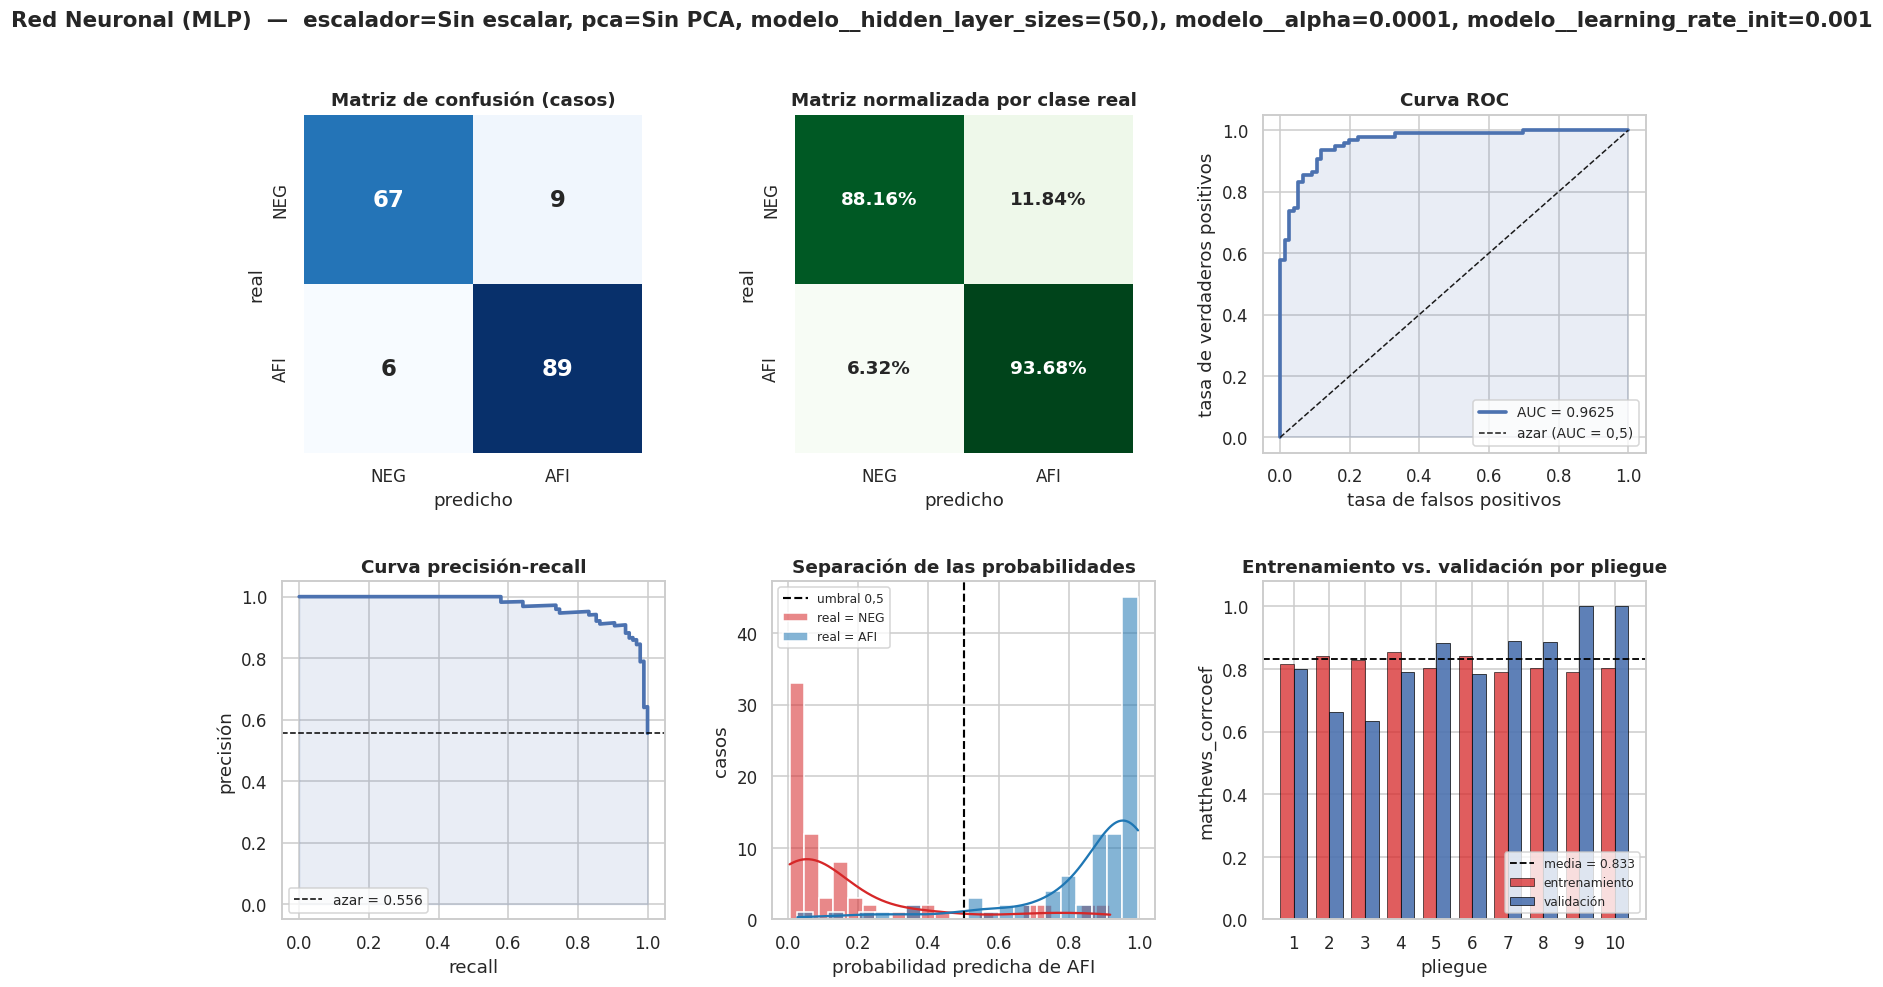


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 9


In [40]:
from sklearn.neural_network import MLPClassifier

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", MLPClassifier(max_iter=2000, random_state=SEMILLA)),
])

grilla = {
         "escalador":               list(ESCALADORES.values()),
         "pca":                     list(OPCIONES_PCA.values()),
         "modelo__hidden_layer_sizes": [(50,), (100,), (50, 25)],
         "modelo__alpha":              [0.0001, 0.001, 0.01],
         "modelo__learning_rate_init": [0.001, 0.01],
}

resultado = evaluar_modelo("Red Neuronal (MLP)", pipeline, grilla)

---
<a id="sec-18"></a>
# 18. LDA (Análisis Discriminante Lineal)

**Cómo funciona.** Asume que las variables predictoras, dentro de cada clase, siguen una
distribución normal multivariada, y que ambas clases comparten la misma matriz de covarianza (la
misma forma de dispersión y correlación entre variables, solo centradas en medias distintas). Con
ese supuesto, la frontera de decisión óptima entre las dos clases resulta ser, matemáticamente, un
hiperplano — de ahí el nombre "lineal". En la práctica, estima las medias de cada clase y la
covarianza compartida a partir de los datos, y clasifica cada caso según de qué media está "más
cerca", en un sentido que tiene en cuenta esa covarianza compartida.

**Fundamentos.** Es un clasificador generativo: en vez de modelar directamente la frontera entre
clases (como SVM o regresión logística), modela cómo se generan los datos dentro de cada clase, y
deriva la frontera a partir de esos modelos. Puede verse también como una técnica de reducción de
dimensionalidad supervisada: encuentra la combinación lineal de variables que mejor separa las
clases, maximizando la distancia entre las medias de las clases en relación a la dispersión dentro
de cada clase.

**Ventajas.** Es rápido de entrenar, funciona bien incluso con relativamente pocos datos (porque
asume una forma particular, no hay que estimar una frontera arbitraria desde cero), y es menos
propenso al sobreajuste que modelos más flexibles, siempre que el supuesto de normalidad y
covarianza compartida sea razonablemente cierto.

**Parámetros de ajuste.**

*  `solver` — el método numérico usado para estimar los parámetros. `"lsqr"` (mínimos cuadrados) y
   `"eigen"` (descomposición en autovalores) son los dos que, junto con `"svd"` (no incluido acá),
   soporta scikit-learn; `"lsqr"` y `"eigen"` son los que admiten además regularización vía
   `shrinkage`. Acá se prueban ambos.
*  `shrinkage` — regulariza la estimación de la covarianza compartida, achicándola hacia una
   covarianza diagonal (variables no correlacionadas); útil cuando hay pocos datos en relación a la
   cantidad de variables, donde la covarianza estimada "a lo bruto" es poco confiable. Rango
   típico: `"auto"` (lo calcula automáticamente) o un número entre 0 (sin regularización, la
   covarianza estimada tal cual) y 1 (covarianza totalmente diagonal). Acá se prueban
   `["auto", 0.1, 0.5]`.


  BÚSQUEDA — LDA
  Parámetros variados    : ['escalador', 'pca', 'modelo__solver', 'modelo__shrinkage']
  Combinaciones evaluadas: 54   (ajustes totales: 540)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__solver,modelo__shrinkage,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Sin escalar,Sin PCA,lsqr,auto,0.8199,0.8327,0.1179,0.0373,-0.0128,0.9110,0.9124,0.0600,0.0068
1,Sin escalar,Sin PCA,eigen,auto,0.8199,0.8327,0.1179,0.0373,-0.0128,0.9110,0.9124,0.0600,0.0066
2,Min-Max,Sin PCA,eigen,auto,0.8199,0.8327,0.1179,0.0373,-0.0128,0.9110,0.9124,0.0600,0.0077
3,Min-Max,Sin PCA,lsqr,auto,0.8199,0.8327,0.1179,0.0373,-0.0128,0.9110,0.9124,0.0600,0.0068
4,Z-score,Sin PCA,lsqr,auto,0.8199,0.8327,0.1179,0.0373,-0.0128,0.9110,0.9124,0.0600,0.0066
5,Z-score,PCA-7,lsqr,auto,0.8186,0.8327,0.1179,0.0373,-0.0141,0.9103,0.9124,0.0600,0.0081
6,Z-score,PCA-6,eigen,0.5000,0.8158,0.8327,0.1179,0.0373,-0.0168,0.9090,0.9124,0.0600,0.0064
7,Z-score,Sin PCA,eigen,auto,0.8199,0.8327,0.1179,0.0373,-0.0128,0.9110,0.9124,0.0600,0.0080
8,Z-score,PCA-6,eigen,auto,0.8132,0.8327,0.1179,0.0373,-0.0194,0.9077,0.9124,0.0600,0.0089
9,Z-score,PCA-7,eigen,0.5000,0.8158,0.8327,0.1179,0.0373,-0.0168,0.9090,0.9124,0.0600,0.0066


  Máximo bruto (matthews_corrcoef = 0.8327): {'escalador': 'Sin escalar', 'pca': 'Sin PCA', 'modelo__solver': 'lsqr', 'modelo__shrinkage': 'auto'}
      cota inferior: 0.7954
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8327): {'escalador': 'Sin escalar', 'pca': 'Sin PCA', 'modelo__solver': 'lsqr', 'modelo__shrinkage': 'auto'}
      cota inferior: 0.7954
  Es la misma combinación que el máximo bruto.
  LDA  —  escalador=Sin escalar, pca=Sin PCA, modelo__solver=lsqr, modelo__shrinkage=auto
    Rendimiento general
      Accuracy               0.9123
    Clase positiva (AFI)
      Precisión              0.9082
      Recall                 0.9368
      F1-score               0.9223
    Promediadas entre clases
      Precisión macro        0.9130
      F1 macro               0.9108
    Independiente del umbral
      ROC-AUC                0.9650

  REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     NEG (0)     0.9178    0.8816    0.8993      

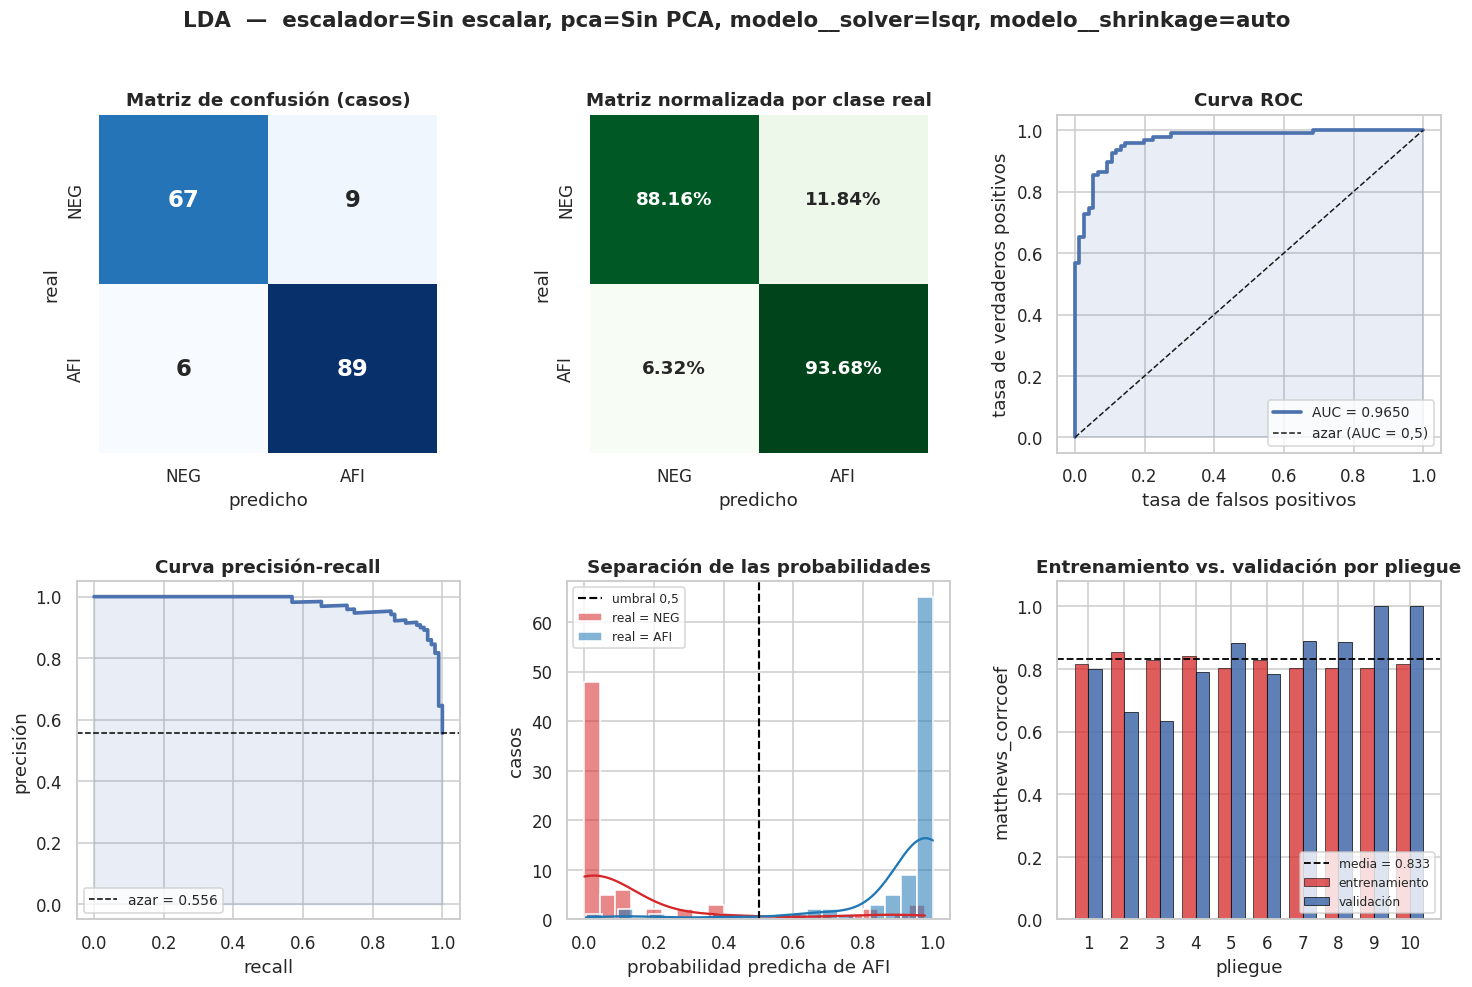


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 10


In [41]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", LinearDiscriminantAnalysis()),
])

grilla = {
         "escalador":       list(ESCALADORES.values()),
         "pca":             list(OPCIONES_PCA.values()),
         "modelo__solver":    ["lsqr", "eigen"],
         "modelo__shrinkage": ["auto", 0.1, 0.5],
}

resultado = evaluar_modelo("LDA", pipeline, grilla)

---
<a id="sec-19"></a>
# 19. AdaBoost

**Cómo funciona.** Es, junto con Gradient Boosting, un método de boosting secuencial, pero con una
mecánica distinta: entrena una secuencia de modelos simples (por defecto, árboles de decisión muy
chicos, de una sola pregunta), y después de cada uno, aumenta el peso de los casos que ese modelo
clasificó mal, para que el siguiente modelo de la secuencia se concentre especialmente en
corregirlos. La predicción final es un voto ponderado de todos los modelos de la secuencia, donde
cada uno pesa según qué tan bien le fue en los datos (ponderados) que le tocaron.

**Fundamentos.** El nombre viene de "Adaptive Boosting": la adaptación está en que los pesos de
los casos se ajustan en cada ronda según los errores de la ronda anterior, en vez de ajustar un
gradiente de error continuo como hace Gradient Boosting. Es, históricamente, uno de los primeros
métodos de boosting con garantías teóricas sólidas: se puede demostrar que, bajo ciertas
condiciones, el error de entrenamiento decrece exponencialmente con la cantidad de rondas.

**Ventajas.** Suele mejorar bastante sobre un árbol de decisión individual con relativamente pocos
modelos en la secuencia, y es menos propenso a sobreajustar que Gradient Boosting cuando se usan
árboles muy simples como base, porque cada modelo individual tiene muy poca capacidad de memorizar
ruido por sí solo.

**Parámetros de ajuste.**

*  `n_estimators` — cantidad de modelos en la secuencia. Rango típico: entero positivo, entre 10 y
   varios cientos; a diferencia de Random Forest, agregar más rondas eventualmente puede
   sobreajustar, aunque más lentamente que en Gradient Boosting. Acá se prueban `[50, 100, 200]`.
*  `learning_rate` — cuánto pesa la contribución de cada modelo de la secuencia a la predicción
   final. Rango típico: positivo, usualmente entre 0,01 y 2; valores chicos necesitan más rondas
   pero son más conservadores, valores grandes convergen más rápido con más riesgo de sobreajuste.
   Acá se prueban `[0.1, 0.5, 1.0]`.


  BÚSQUEDA — AdaBoost
  Parámetros variados    : ['escalador', 'pca', 'modelo__n_estimators', 'modelo__learning_rate']
  Combinaciones evaluadas: 81   (ajustes totales: 810)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__n_estimators,modelo__learning_rate,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Sin escalar,PCA-7,50,0.1000,0.8380,0.8488,0.1147,0.0363,-0.0108,0.9194,0.9186,0.0641,0.1058
1,Sin escalar,PCA-7,100,0.1000,0.8435,0.8488,0.1147,0.0363,-0.0053,0.9220,0.9186,0.0641,0.2181
2,Sin escalar,PCA-6,50,0.1000,0.8380,0.8488,0.1147,0.0363,-0.0108,0.9194,0.9186,0.0641,0.1062
3,Sin escalar,PCA-6,100,0.1000,0.8435,0.8488,0.1147,0.0363,-0.0053,0.9220,0.9186,0.0641,0.2078
4,Min-Max,PCA-6,50,1.0000,0.9935,0.8401,0.0764,0.0242,0.1533,0.9968,0.9183,0.0385,0.1094
...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,Sin escalar,Sin PCA,100,0.1000,0.8979,0.7441,0.1219,0.0386,0.1538,0.9493,0.8660,0.0628,0.3039
77,Min-Max,Sin PCA,100,0.1000,0.8979,0.7441,0.1219,0.0386,0.1538,0.9493,0.8660,0.0628,0.2108
78,Z-score,Sin PCA,100,0.1000,0.8979,0.7441,0.1219,0.0386,0.1538,0.9493,0.8660,0.0628,0.2987
79,Z-score,PCA-7,200,1.0000,1.0000,0.7407,0.1275,0.0403,0.2593,1.0000,0.8657,0.0641,0.4179


  Máximo bruto (matthews_corrcoef = 0.8488): {'escalador': 'Sin escalar', 'pca': 'PCA-7', 'modelo__n_estimators': np.int64(50), 'modelo__learning_rate': np.float64(0.1)}
      cota inferior: 0.8125
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8401): {'escalador': 'Min-Max', 'pca': 'PCA-6', 'modelo__n_estimators': np.int64(50), 'modelo__learning_rate': np.float64(1.0)}
      cota inferior: 0.8160
  Cede 0.0087 de matthews_corrcoef frente al máximo bruto, a cambio de un desvío menor entre pliegues (resultado más confiable).
  ADABOOST  —  escalador=Min-Max, pca=PCA-6, modelo__n_estimators=50, modelo__learning_rate=1.0
    Rendimiento general
      Accuracy               0.9181
    Clase positiva (AFI)
      Precisión              0.9091
      Recall                 0.9474
      F1-score               0.9278
    Promediadas entre clases
      Precisión macro        0.9198
      F1 macro               0.9166
    Independiente del umbral
      ROC-AUC                0.9542

 

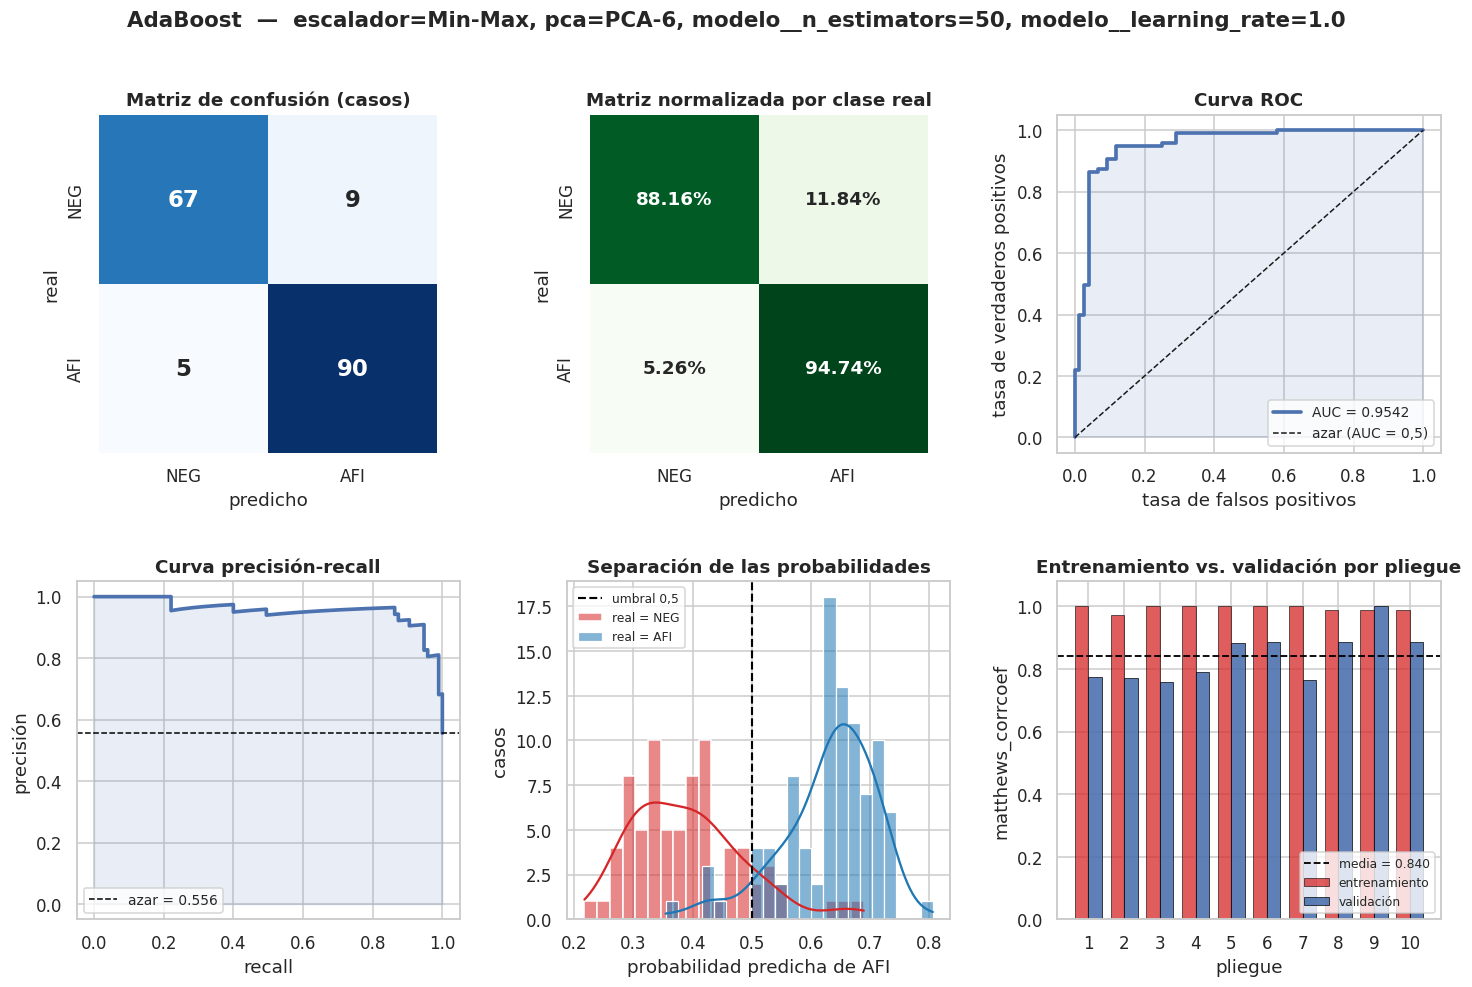


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 11


In [42]:
from sklearn.ensemble import AdaBoostClassifier

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", AdaBoostClassifier(random_state=SEMILLA)),
])

grilla = {
         "escalador":            list(ESCALADORES.values()),
         "pca":                  list(OPCIONES_PCA.values()),
         "modelo__n_estimators":  [50, 100, 200],
         "modelo__learning_rate": [0.1, 0.5, 1.0],
}

resultado = evaluar_modelo("AdaBoost", pipeline, grilla)

---
<a id="sec-20"></a>
# 20. QDA (Análisis Discriminante Cuadrático)

**Cómo funciona.** Es la contraparte directa de LDA (punto 18), con un supuesto menos
restrictivo: también asume que cada clase sigue una distribución normal multivariada, pero ya no
exige que ambas clases comparten la misma covarianza — cada clase estima la suya propia. Al no
compartir covarianza, la frontera de decisión que resulta de ese supuesto ya no es un hiperplano,
sino una superficie cuadrática (de ahí el nombre): puede ser una curva, una elipse, una parábola,
según cómo difieran las covarianzas de ambas clases.

**Fundamentos.** Al igual que LDA, es un clasificador generativo que deriva la frontera a partir
de modelar cómo se distribuyen los datos dentro de cada clase; la diferencia es, exclusivamente,
que QDA le permite a cada clase tener su propia forma de dispersión y correlación entre variables.
Esa flexibilidad extra tiene un costo: hay más parámetros que estimar (una matriz de covarianza
completa por clase, en vez de una sola compartida), por lo que QDA necesita, en general, más datos
que LDA para estimar esos parámetros con confianza.

**Ventajas.** Puede capturar fronteras de decisión curvas sin la complejidad computacional de un
kernel o de una red neuronal, y es preferible a LDA exactamente cuando hay evidencia de que la
dispersión de las variables es genuinamente distinta entre las dos clases — algo que vale la pena
comparar directamente, dado que ambos modelos están en este mismo cuaderno.

**Parámetros de ajuste.**

*  `reg_param` — regulariza la estimación de la covarianza de cada clase, achicándola hacia una
   covarianza compartida entre clases (como la de LDA); ayuda cuando hay pocos datos por clase en
   relación a la cantidad de variables, donde las covarianzas separadas se estiman con poca
   confianza. Rango típico: entre 0 (covarianzas completamente separadas, QDA "puro") y 1
   (covarianzas iguales entre clases, equivalente a LDA sin shrinkage). Acá se prueban
   `[0.0, 0.1, 0.3, 0.5]`.


  BÚSQUEDA — QDA
  Parámetros variados    : ['escalador', 'pca', 'modelo__reg_param']
  Combinaciones evaluadas: 36   (ajustes totales: 360)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__reg_param,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Z-score,PCA-7,0.5000,0.8253,0.8313,0.1072,0.0339,-0.0060,0.9136,0.9124,0.0539,0.0072
1,Z-score,PCA-6,0.5000,0.8253,0.8313,0.1072,0.0339,-0.0060,0.9136,0.9124,0.0539,0.0068
2,Z-score,Sin PCA,0.5000,0.8253,0.8313,0.1072,0.0339,-0.0060,0.9136,0.9124,0.0539,0.0058
3,Z-score,PCA-7,0.3000,0.8265,0.8202,0.0941,0.0298,0.0063,0.9142,0.9065,0.0468,0.0053
4,Z-score,Sin PCA,0.3000,0.8265,0.8202,0.0941,0.0298,0.0063,0.9142,0.9065,0.0468,0.0041
5,Z-score,PCA-6,0.3000,0.8265,0.8202,0.0941,0.0298,0.0063,0.9142,0.9065,0.0468,0.0076
6,Z-score,Sin PCA,0.0000,0.7966,0.8062,0.1352,0.0428,-0.0096,0.8993,0.9007,0.0646,0.0045
7,Sin escalar,PCA-6,0.0000,0.8142,0.8027,0.1261,0.0399,0.0115,0.9084,0.9007,0.0590,0.0039
8,Z-score,PCA-6,0.0000,0.8142,0.8027,0.1261,0.0399,0.0115,0.9084,0.9007,0.0590,0.0048
9,Min-Max,PCA-6,0.0000,0.8142,0.8027,0.1261,0.0399,0.0115,0.9084,0.9007,0.0590,0.0048


  Máximo bruto (matthews_corrcoef = 0.8313): {'escalador': 'Z-score', 'pca': 'Sin PCA', 'modelo__reg_param': np.float64(0.5)}
      cota inferior: 0.7974
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8313): {'escalador': 'Z-score', 'pca': 'Sin PCA', 'modelo__reg_param': np.float64(0.5)}
      cota inferior: 0.7974
  Es la misma combinación que el máximo bruto.
  QDA  —  escalador=Z-score, pca=Sin PCA, modelo__reg_param=0.5
    Rendimiento general
      Accuracy               0.9123
    Clase positiva (AFI)
      Precisión              0.9000
      Recall                 0.9474
      F1-score               0.9231
    Promediadas entre clases
      Precisión macro        0.9148
      F1 macro               0.9105
    Independiente del umbral
      ROC-AUC                0.9518

  REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     NEG (0)     0.9296    0.8684    0.8980        76
     AFI (1)     0.9000    0.9474    0.9231        95

    accu

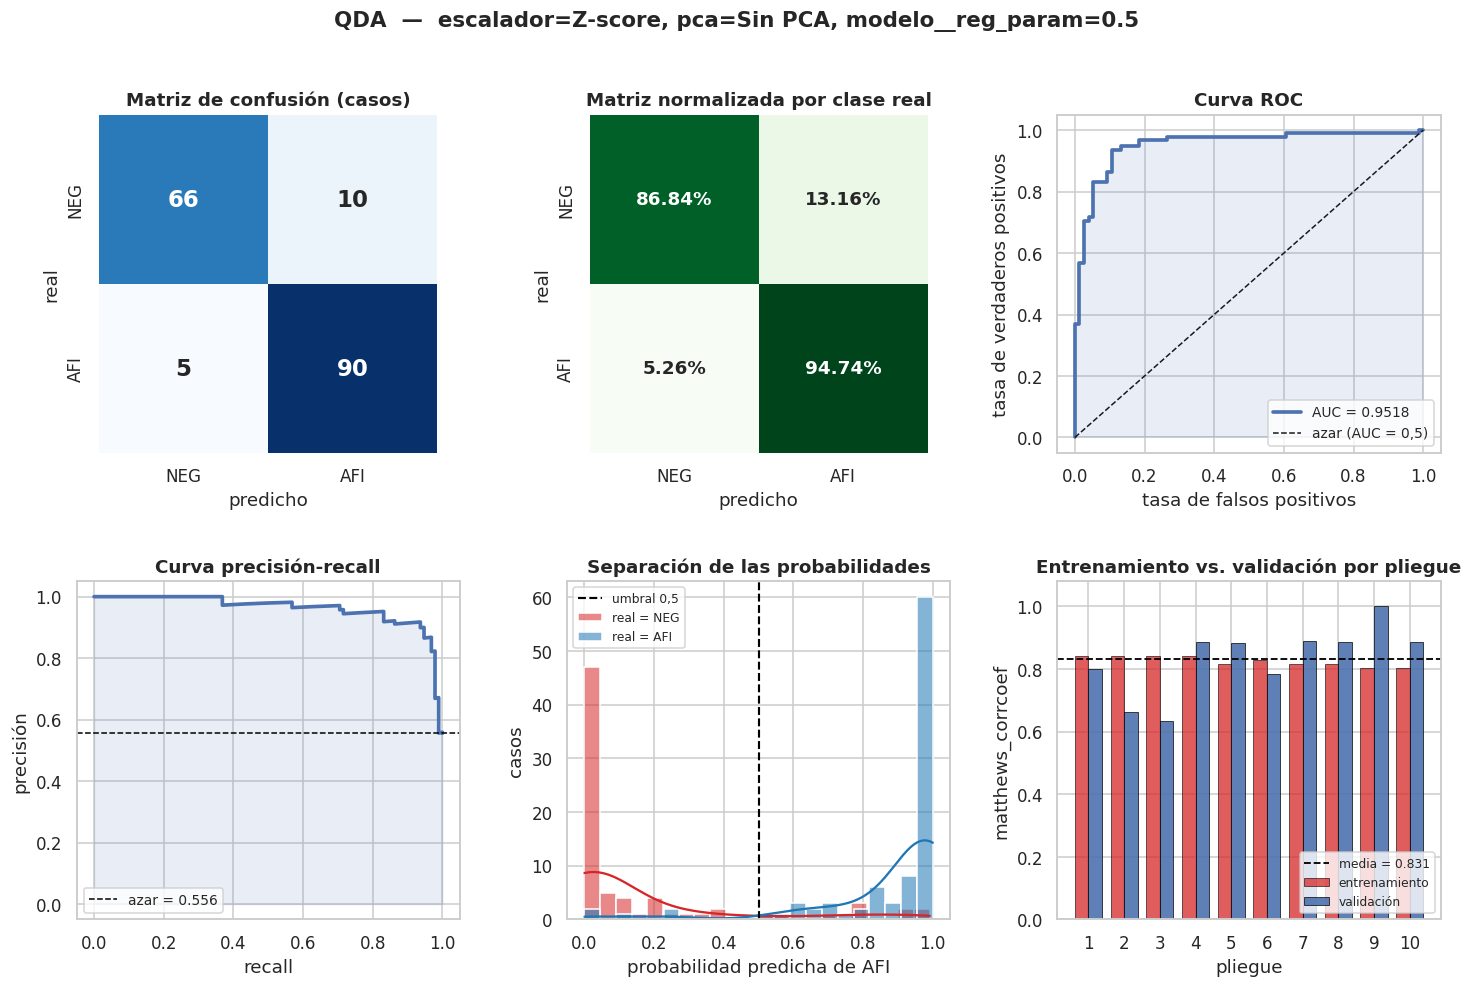


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 12


In [43]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", QuadraticDiscriminantAnalysis()),
])

grilla = {
         "escalador":         list(ESCALADORES.values()),
         "pca":               list(OPCIONES_PCA.values()),
         "modelo__reg_param":  [0.0, 0.1, 0.3, 0.5],
}

resultado = evaluar_modelo("QDA", pipeline, grilla)

---
<a id="sec-21"></a>
# 21. HistGradientBoosting

**Cómo funciona.** Es, en esencia, el mismo principio que Gradient Boosting (punto 15) —una
secuencia de árboles que corrigen el error de los anteriores—, pero con una implementación mucho
más eficiente: en vez de evaluar todos los puntos de corte posibles de cada variable continua,
agrupa los valores de cada variable en un número fijo de "bins" (como un histograma) y solo
considera los cortes entre bins. Esto reduce drásticamente el costo de construir cada árbol, a
cambio de una pérdida de precisión mínima en los puntos de corte.

**Fundamentos.** Es la implementación nativa de scikit-learn del enfoque popularizado por
LightGBM y XGBoost (boosting basado en histogramas), que es hoy el estándar de facto para
boosting de árboles en datasets de tamaño mediano a grande, justamente por esa eficiencia. Además
de discretizar las variables, maneja nativamente los valores faltantes (no hace falta imputarlos
antes de entrenar), aunque en este cuaderno no se aprovecha esa característica porque el dataset
ya llega completo desde la Parte 2A.

**Ventajas.** Entrena considerablemente más rápido que Gradient Boosting clásico en datasets más
grandes, manteniendo un desempeño muy similar (o mejor), y escala mejor a medida que crece la
cantidad de datos o de árboles en la secuencia.

**Parámetros de ajuste.**

*  `max_iter` — cantidad de árboles de la secuencia (el equivalente a `n_estimators` en Gradient
   Boosting clásico). Rango típico: entero positivo, entre 50 y varios cientos. Acá se prueban
   `[100, 200]`.
*  `learning_rate` — igual que en Gradient Boosting, cuánto pesa cada árbol nuevo sobre la
   predicción acumulada. Rango típico: positivo, entre 0,01 y 0,3. Acá se prueban
   `[0.05, 0.1, 0.2]`.
*  `max_depth` — profundidad máxima de cada árbol de la secuencia. Rango típico: `None` (el límite
   real lo pone, en este modelo, la cantidad máxima de hojas) o un entero entre 2 y 10. Acá se
   prueban `[3, 5, None]`.


  BÚSQUEDA — HistGradientBoosting
  Parámetros variados    : ['escalador', 'pca', 'modelo__max_iter', 'modelo__learning_rate', 'modelo__max_depth']
  Combinaciones evaluadas: 162   (ajustes totales: 1620)
  Métrica que decide     : matthews_corrcoef   (resto solo informativa)


,escalador,pca,modelo__max_iter,modelo__learning_rate,modelo__max_depth,matthews_corrcoef_entrena,matthews_corrcoef_validacion,matthews_corrcoef_desvio,error_estandar,brecha,accuracy_entrena,accuracy_validacion,accuracy_desvio,tiempo_ajuste_seg
0,Sin escalar,PCA-7,100,0.0500,3,0.9409,0.8221,0.1238,0.0391,0.1188,0.9707,0.9069,0.0643,0.0456
1,Sin escalar,PCA-6,100,0.0500,3,0.9396,0.8221,0.1238,0.0391,0.1175,0.9701,0.9069,0.0643,0.0477
2,Min-Max,PCA-6,100,0.0500,3,0.9330,0.8127,0.0866,0.0274,0.1203,0.9669,0.9007,0.0457,0.0476
3,Min-Max,PCA-7,200,0.1000,3,1.0000,0.8127,0.0866,0.0274,0.1873,1.0000,0.9007,0.0457,0.1352
4,Min-Max,PCA-7,100,0.0500,3,0.9356,0.8127,0.0866,0.0274,0.1230,0.9682,0.9007,0.0457,0.0486
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,Z-score,PCA-6,200,0.1000,3,1.0000,0.7271,0.1573,0.0497,0.2729,1.0000,0.8605,0.0811,0.1357
158,Z-score,PCA-6,100,0.2000,3,1.0000,0.7271,0.1573,0.0497,0.2729,1.0000,0.8605,0.0811,0.0485
159,Z-score,PCA-6,200,0.2000,3,1.0000,0.7271,0.1573,0.0497,0.2729,1.0000,0.8605,0.0811,0.0882
160,Z-score,PCA-6,100,0.2000,Sin escalar,1.0000,0.7271,0.1573,0.0497,0.2729,1.0000,0.8605,0.0811,0.0819


  Máximo bruto (matthews_corrcoef = 0.8221): {'escalador': 'Sin escalar', 'pca': 'PCA-7', 'modelo__max_iter': np.int64(100), 'modelo__learning_rate': np.float64(0.05), 'modelo__max_depth': 3}
      cota inferior: 0.7829
  ELEGIDA por cota inferior más alta (matthews_corrcoef = 0.8127): {'escalador': 'Min-Max', 'pca': 'PCA-7', 'modelo__max_iter': np.int64(100), 'modelo__learning_rate': np.float64(0.05), 'modelo__max_depth': 3}
      cota inferior: 0.7853
  Cede 0.0094 de matthews_corrcoef frente al máximo bruto, a cambio de un desvío menor entre pliegues (resultado más confiable).
  HISTGRADIENTBOOSTING  —  escalador=Min-Max, pca=PCA-7, modelo__max_iter=100, modelo__learning_rate=0.05, modelo__max_depth=3
    Rendimiento general
      Accuracy               0.9006
    Clase positiva (AFI)
      Precisión              0.9149
      Recall                 0.9053
      F1-score               0.9101
    Promediadas entre clases
      Precisión macro        0.8990
      F1 macro              

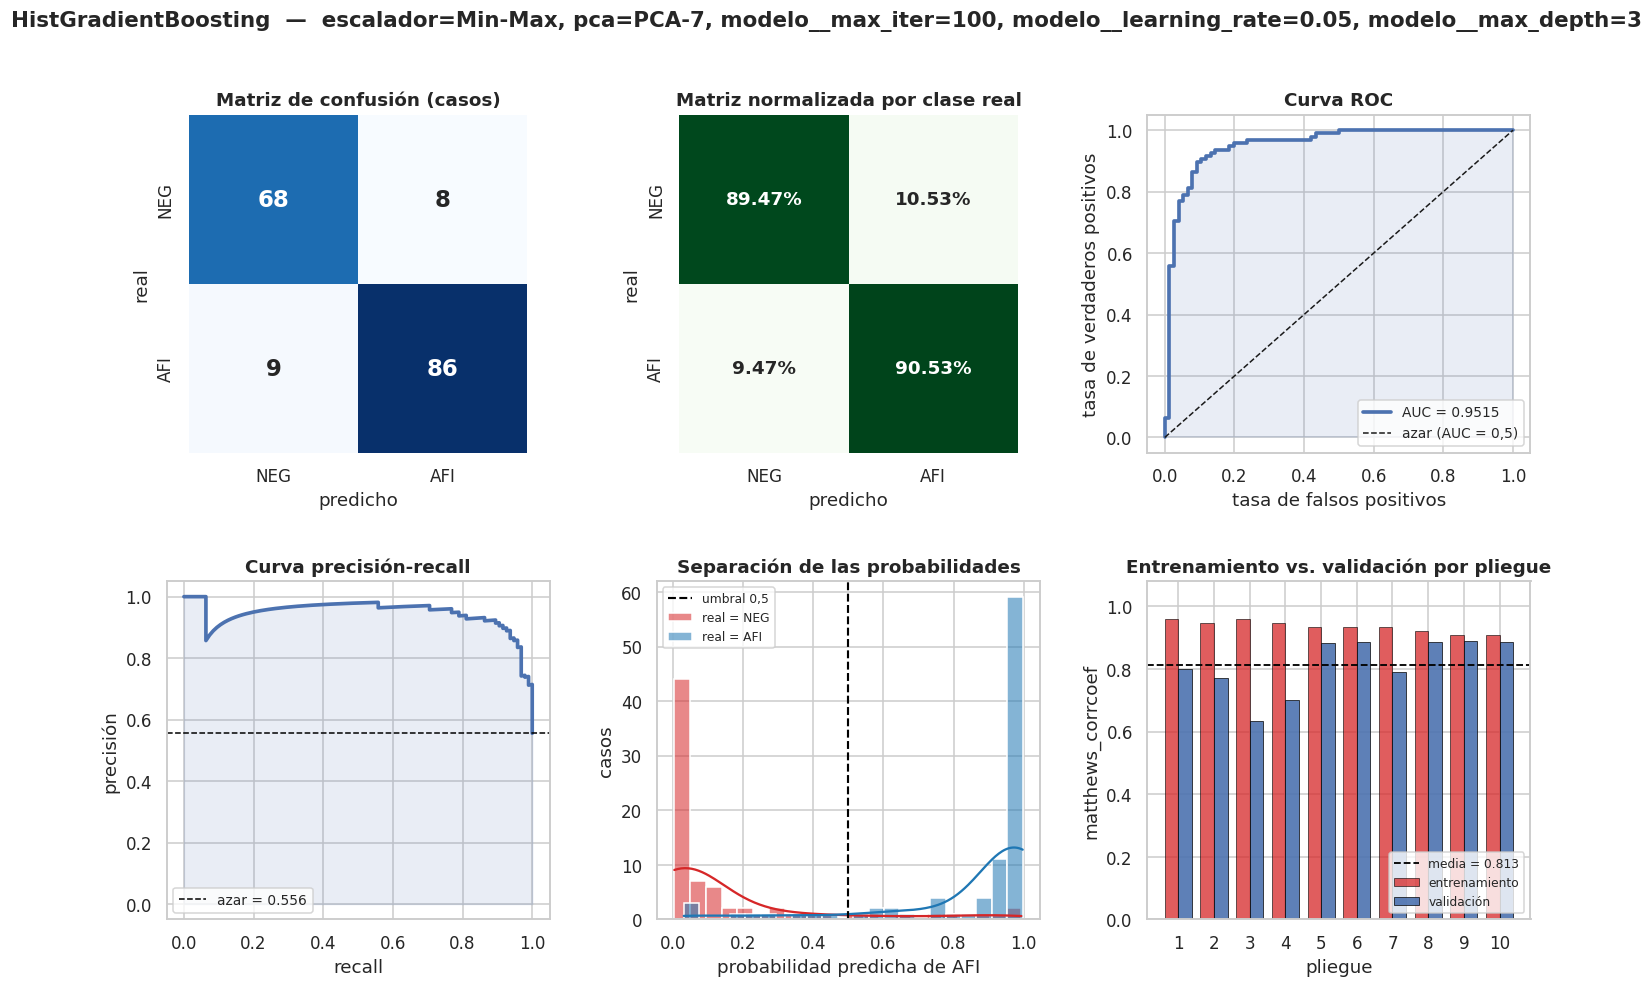


Guardado en RESULTADOS. Modelos acumulados hasta ahora: 13


In [44]:
from sklearn.ensemble import HistGradientBoostingClassifier

pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(random_state=SEMILLA)),
    ("modelo", HistGradientBoostingClassifier(random_state=SEMILLA)),
])

grilla = {
         "escalador":           list(ESCALADORES.values()),
         "pca":                 list(OPCIONES_PCA.values()),
         "modelo__max_iter":     [100, 200],
         "modelo__learning_rate": [0.05, 0.1, 0.2],
         "modelo__max_depth":     [3, 5, None],
}

resultado = evaluar_modelo("HistGradientBoosting", pipeline, grilla)

---
# 22. Comparación final

<a id="sec-22-1"></a>
## 22.1 Quién ganó

`mostrar_ganador()` busca, entre todos los modelos ya evaluados en `RESULTADOS`, el que tiene el
mejor valor de `METRICA_DECISION` —la misma métrica que decidió en cada búsqueda de grilla— y
muestra su resumen completo (texto y gráficos) reutilizando lo que ya quedó guardado en
`DETALLES_MODELOS` en el punto 9.5, sin volver a entrenar ni a predecir nada.


In [45]:
def mostrar_ganador():
    # Busca, entre todos los modelos ya evaluados, el mejor según METRICA_DECISION (la misma
    # métrica que decide en cada búsqueda de grilla), y muestra su resumen completo reusando
    # los datos ya calculados en evaluar_modelo() — sin volver a correr nada.
    maestra = pd.DataFrame(RESULTADOS)
    if not len(maestra):
        print("Todavía no se corrió ningún modelo.")
        return

    fila_ganadora = maestra.sort_values(METRICA_DECISION, ascending=False).iloc[0]
    nombre_ganador = fila_ganadora["modelo"]

    print("=" * 88)
    print(f"  MEJOR MODELO (según {METRICA_DECISION}): {nombre_ganador}")
    print(f"  {METRICA_DECISION} = {fila_ganadora[METRICA_DECISION]:.4f}")
    print("=" * 88)

    datos = DETALLES_MODELOS[nombre_ganador]
    muestra_metricas(nombre_ganador, y, datos["y_pred"], datos["metricas"], subtitulo=datos["subtitulo"])
    diagnostico_ajuste(datos["detalle"])
    graficos(nombre_ganador, y, datos["y_pred"], datos["y_proba"], datos["metricas"], datos["detalle"],
            subtitulo=datos["subtitulo"], n_pliegues=N_PLIEGUES)

<a id="sec-22-2"></a>
## 22.2 La tabla comparativa

Arma `maestra`, la tabla con una fila por modelo evaluado hasta el momento, ordenada de mejor a
peor según `METRICA_DECISION`, y muestra las columnas más relevantes para comparar de un vistazo:
el modelo, su escalador y PCA elegidos, sus métricas principales, y el tiempo de ajuste de su mejor
combinación. Si todavía no se corrió ningún modelo, avisa en vez de fallar. Al final, llama a
`mostrar_ganador()` (punto 22.1) para mostrar el resumen completo del primero de la tabla.


,modelo,escalador,pca,accuracy,f1_macro,roc_auc,tiempo_ajuste_seg
0,Árbol de Decisión,Sin escalar,PCA-7,0.9181,0.9175,0.9413,0.0042
1,Gradient Boosting,Sin escalar,PCA-6,0.9181,0.9173,0.9357,0.1275
2,AdaBoost,Min-Max,PCA-6,0.9181,0.9166,0.9542,0.1094
3,Random Forest,Sin escalar,NaN,0.9123,0.9113,0.9575,0.7451
4,QDA,Z-score,Sin PCA,0.9123,0.9105,0.9518,0.0058
5,LDA,Sin escalar,Sin PCA,0.9123,0.9108,0.9650,0.0068
6,SVM,Sin escalar,Sin PCA,0.9123,0.9108,0.9589,0.0062
7,Regresión Logística,Min-Max,Sin PCA,0.9123,0.9108,0.9637,0.0104
8,Regresión Logística,Min-Max,Sin PCA,0.9123,0.9108,0.9637,0.0079
9,Red Neuronal (MLP),Sin escalar,Sin PCA,0.9123,0.9108,0.9625,0.2674


  MEJOR MODELO (según matthews_corrcoef): Árbol de Decisión
  matthews_corrcoef = 0.8360
  ÁRBOL DE DECISIÓN  —  escalador=Sin escalar, pca=PCA-7, modelo__max_depth=Sin escalar, modelo__min_samples_leaf=20, modelo__criterion=entropy
    Rendimiento general
      Accuracy               0.9181
    Clase positiva (AFI)
      Precisión              0.9451
      Recall                 0.9053
      F1-score               0.9247
    Promediadas entre clases
      Precisión macro        0.9163
      F1 macro               0.9175
    Independiente del umbral
      ROC-AUC                0.9413

  REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     NEG (0)     0.8875    0.9342    0.9103        76
     AFI (1)     0.9451    0.9053    0.9247        95

    accuracy                         0.9181       171
   macro avg     0.9163    0.9197    0.9175       171
weighted avg     0.9195    0.9181    0.9183       171


  DIAGNÓSTICO DE AJUSTE  (matthews_corrcoef por plie

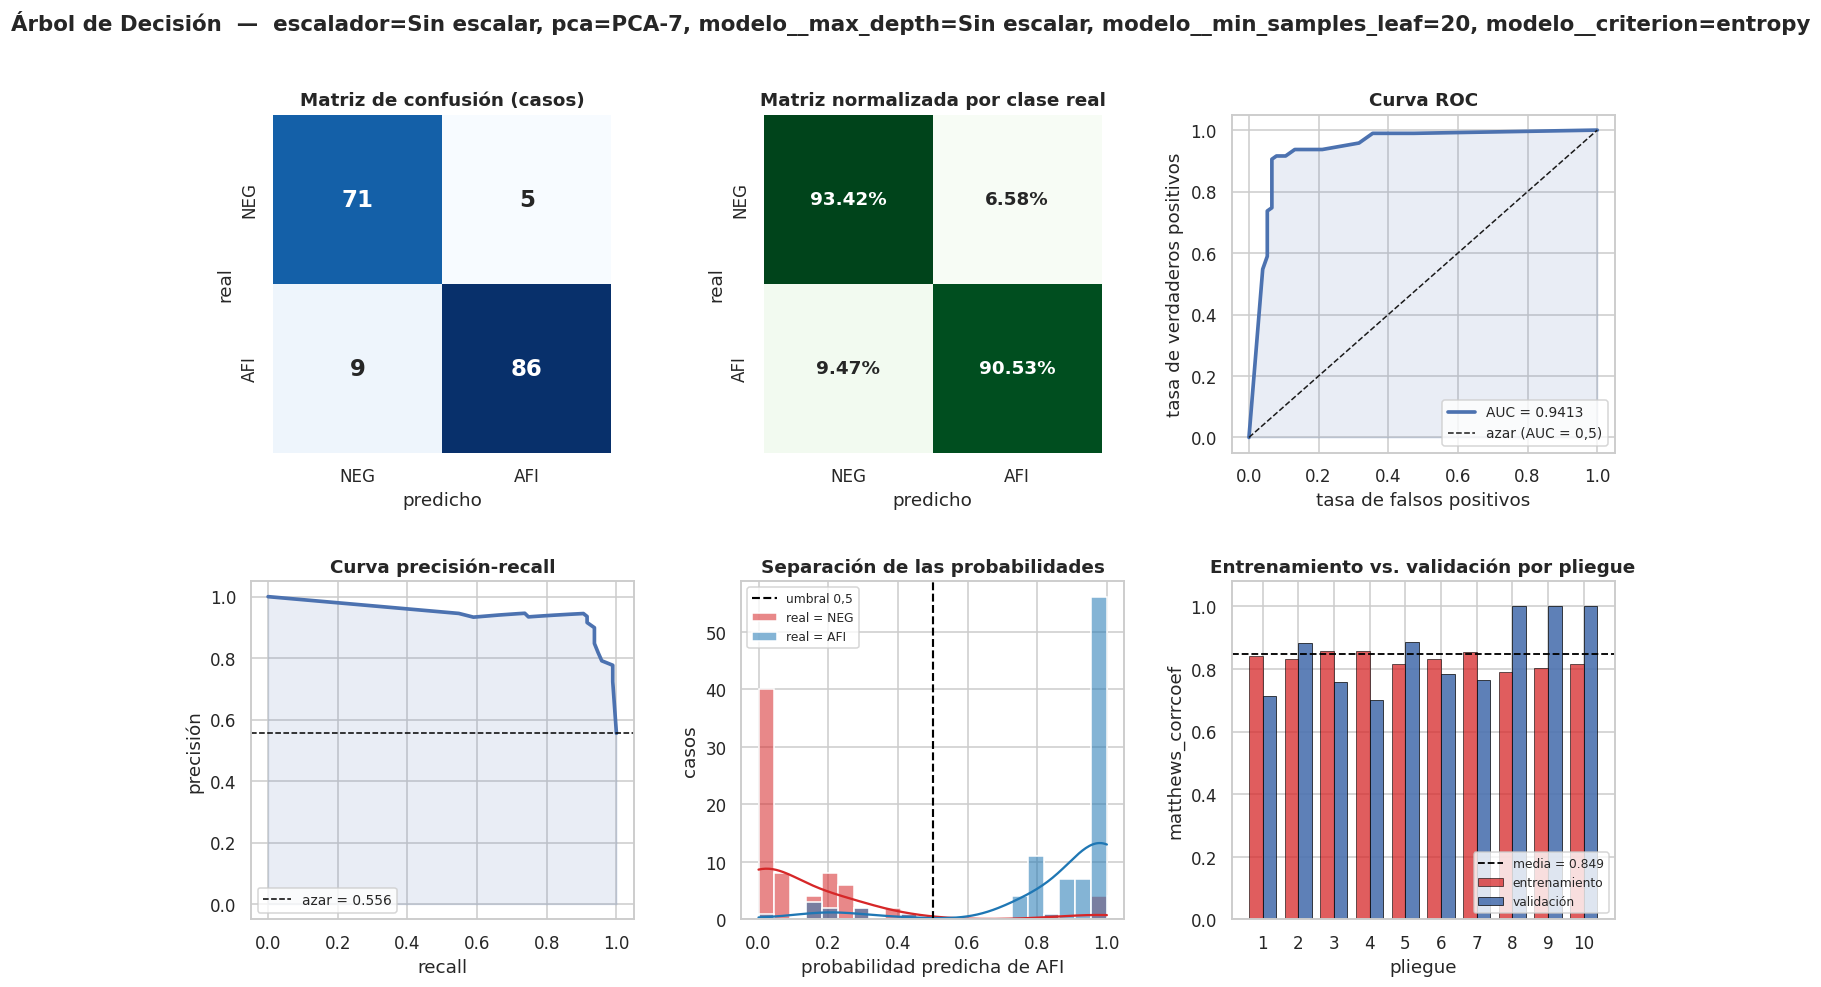

In [46]:
maestra = pd.DataFrame(RESULTADOS)
if len(maestra):
    display(maestra.sort_values(METRICA_DECISION, ascending=False)
        [["modelo", "escalador", "pca", "accuracy", "f1_macro", "roc_auc", "tiempo_ajuste_seg"]]
        .reset_index(drop=True))
    mostrar_ganador()
else:
    print("Todavía no se corrió ningún modelo.")

<a id="sec-22-3"></a>
## 22.3 Exportar los resultados para reproducirlos

Guarda `maestra` en un CSV, agregándole antes las columnas de configuración que hacen falta para
poder reproducir exactamente esta comparación más adelante — la semilla, la cantidad de pliegues y
qué métrica decidió y cuál fue la extra —, y además incluye, para cada modelo, todos los
hiperparámetros de su mejor combinación (cada uno en su propia columna, con `NaN` en los modelos a
los que ese hiperparámetro no les aplica). En Colab, intenta descargar el archivo
automáticamente; si no está en Colab, avisa que hay que descargarlo manualmente desde el panel de
archivos.


In [47]:
# Guarda la tabla comparativa final para poder descargarla y reproducirla.
nombre_archivo = "resultados_modelos.csv"

exportable = maestra.assign(
    semilla=SEMILLA,
    n_pliegues=N_PLIEGUES,
    metrica_decision=METRICA_DECISION,
    metrica_extra=METRICA_EXTRA,
).sort_values(METRICA_DECISION, ascending=False)

exportable.to_csv(nombre_archivo, index=False)
print(f"Guardado: {nombre_archivo}  ({len(exportable.columns)} columnas)")

try:
    from google.colab import files
    files.download(nombre_archivo)
except ImportError:
    print("No estás en Colab — descargalo manualmente desde el panel de archivos de la izquierda (ícono de carpeta).")

Guardado: resultados_modelos.csv  (34 columnas)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>